# Task A: Current GSTD Classification — Final Technical Notebook

This notebook is the final technical deliverable for **Task A**, where the goal is to classify the crop's current growth stage (**GSTD**) using the validated project dataset.

The notebook keeps the full modeling progression because each step answers a different handoff question:

1. Can current GSTD be predicted well with the broader DSSAT feature space?
2. Does the result still hold after removing the strongest stage-like proxy variables?
3. How well does a more practical feature set perform?
4. Can the smaller client-feasible feature set support Task A?
5. How much do `LAID` and short-term time-series features help?

The main validation strategy is **GroupKFold by `RUNNO`**, so observations from the same simulation run do not appear in both training and validation folds. A treatment-held-out test is also included as an additional robustness check.


## Notebook setup and dataset load

This first section loads the final validated dataset, sorts the data in run/date order, defines `GSTD` as the Task A target, and builds the initial numeric feature matrix. The final handoff assumes the dataset file is named `final_validated_dataset.csv`.


In [1]:
# ============================================================
# SECTION A1: LOAD DATA FOR TASK A (CURRENT GROWTH STAGE)
# ============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from pathlib import Path

from lightgbm import LGBMClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Load the final validated dataset. The fallback paths make the notebook easier to run from either the root folder or the final handoff folder.
candidate_paths = [
    Path("final_validated_dataset.csv"),
    Path("../02_Data/final_validated_dataset.csv"),
    Path("02_Data/final_validated_dataset.csv")
]

DATA_PATH = next((path for path in candidate_paths if path.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Could not find final_validated_dataset.csv. "
        "Place it next to this notebook or inside the 02_Data folder."
    )

print("Using dataset:", DATA_PATH)
df = pd.read_csv(DATA_PATH)

print("Raw shape:", df.shape)
print("Unique runs:", df["RUNNO"].nunique())
print("Unique treatments:", df["TRTNO"].nunique())

# Make a clean sorted copy so the time-series feature steps later use the right row order.
df = df.copy()

# Ensure DATE is datetime if present
if "DATE" in df.columns:
    df["DATE"] = pd.to_datetime(df["DATE"], errors="coerce")

sort_cols = [c for c in ["RUNNO", "DATE", "DAP"] if c in df.columns]
df = df.sort_values(sort_cols).reset_index(drop=True)

# Task A only uses rows where the current growth stage is available.
df = df[df["GSTD"].notna()].copy()

# DSSAT stages seen in current data
valid_stages = sorted(df["GSTD"].dropna().unique())
print("\nObserved GSTD classes:", valid_stages)

print("\nClass counts:")
print(df["GSTD"].value_counts().sort_index())

print("\nClass proportions:")
print(df["GSTD"].value_counts(normalize=True).sort_index().round(4))

# Set up the target and grouping column for the modeling steps.
target_col = "GSTD"
group_col = "RUNNO"

# Remove identifiers, direct time shortcuts, and label columns so the baseline is still honest.
# These columns would either leak the answer or do not belong in the numeric feature matrix.
exclude_cols = {
    target_col,
    "RUNNO",
    "TRTNO",
    "TRTNA",
    "DATE",
    "YEAR",
    "DOY",
    "DAS",
    "DAP",
    "WDATE"
}

# Start with numeric model-ready columns for the first benchmark.
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
feature_cols = [c for c in numeric_cols if c not in exclude_cols]

X = df[feature_cols].copy()
y = df[target_col].astype(int).copy()
groups = df[group_col].copy()

print("\nFeature count (strict baseline):", len(feature_cols))
print("Example features:", feature_cols[:25])

# Quick checks before modeling, so we can catch obvious data issues early.
print("\nMissingness summary (top 20):")
missing_summary = X.isna().mean().sort_values(ascending=False)
print(missing_summary.head(20))

print("\nFinal modeling shapes:")
print("X:", X.shape)
print("y:", y.shape)
print("groups:", groups.shape)

Using dataset: final_validated_dataset.csv
Raw shape: (135240, 141)
Unique runs: 980
Unique treatments: 35

Observed GSTD classes: [np.int64(0), np.int64(1), np.int64(3), np.int64(5), np.int64(7), np.int64(8)]

Class counts:
GSTD
0    41261
1     6164
3     4847
5    34613
7    14700
8    33655
Name: count, dtype: int64

Class proportions:
GSTD
0    0.3051
1    0.0456
3    0.0358
5    0.2559
7    0.1087
8    0.2489
Name: proportion, dtype: float64

Feature count (strict baseline): 131
Example features: ['L#SD', 'LAID', 'LWAD', 'SWAD', 'GWAD', 'LIWAM', 'LINTP', 'RWAD', 'VWAD', 'CWAD', 'G#AD', 'GWGD', 'HIAD', 'PWAD', 'P#AD', 'WSPD', 'WSGD', 'NSTD', 'PST1A', 'PST2A', 'KSTD', 'EWSD', 'LN%D', 'SH%D', 'HIPD']

Missingness summary (top 20):
L#SD    0.0
NT2D    0.0
NH10    0.0
NH9D    0.0
NH8D    0.0
NH7D    0.0
NH6D    0.0
NH5D    0.0
NH4D    0.0
NH3D    0.0
NH2D    0.0
NH1D    0.0
NI10    0.0
NI9D    0.0
NI8D    0.0
NI7D    0.0
NI6D    0.0
NI5D    0.0
NI4D    0.0
NI3D    0.0
dtype: float64



Fold 1/5
Accuracy           : 0.9956
Balanced Accuracy  : 0.9957
Macro F1           : 0.9950
Weighted F1        : 0.9956
Fold 2/5
Accuracy           : 0.9949
Balanced Accuracy  : 0.9949
Macro F1           : 0.9942
Weighted F1        : 0.9950
Fold 3/5
Accuracy           : 0.9948
Balanced Accuracy  : 0.9954
Macro F1           : 0.9941
Weighted F1        : 0.9948
Fold 4/5
Accuracy           : 0.9949
Balanced Accuracy  : 0.9948
Macro F1           : 0.9938
Weighted F1        : 0.9949
Fold 5/5
Accuracy           : 0.9947
Balanced Accuracy  : 0.9949
Macro F1           : 0.9937
Weighted F1        : 0.9947

FOLD-LEVEL RESULTS


,fold,n_train,n_valid,accuracy,balanced_accuracy,macro_f1,weighted_f1
0,1,108192,27048,0.995563,0.995719,0.994974,0.995579
1,2,108192,27048,0.994935,0.994937,0.994160,0.994951
2,3,108192,27048,0.994787,0.995395,0.994064,0.994806
3,4,108192,27048,0.994861,0.994767,0.993801,0.994880
4,5,108192,27048,0.994676,0.994886,0.993725,0.994696



Mean CV Metrics:
accuracy             0.9950
balanced_accuracy    0.9951
macro_f1             0.9941
weighted_f1          0.9950
dtype: float64

OVERALL OUT-OF-FOLD RESULTS
Accuracy           : 0.9950
Balanced Accuracy  : 0.9951
Macro F1           : 0.9941
Weighted F1        : 0.9950

Classification Report (OOF):


,precision,recall,f1-score,support
0,0.999709,0.999758,0.999733,41261.000000
1,0.997891,0.997891,0.997891,6164.000000
3,0.998145,0.999175,0.998660,4847.000000
5,0.997396,0.995753,0.996574,34613.000000
7,0.968529,0.988163,0.978248,14700.000000
8,0.997456,0.990105,0.993767,33655.000000
accuracy,0.994965,0.994965,0.994965,0.994965
macro avg,0.993188,0.995141,0.994145,135240.000000
weighted avg,0.995028,0.994965,0.994982,135240.000000


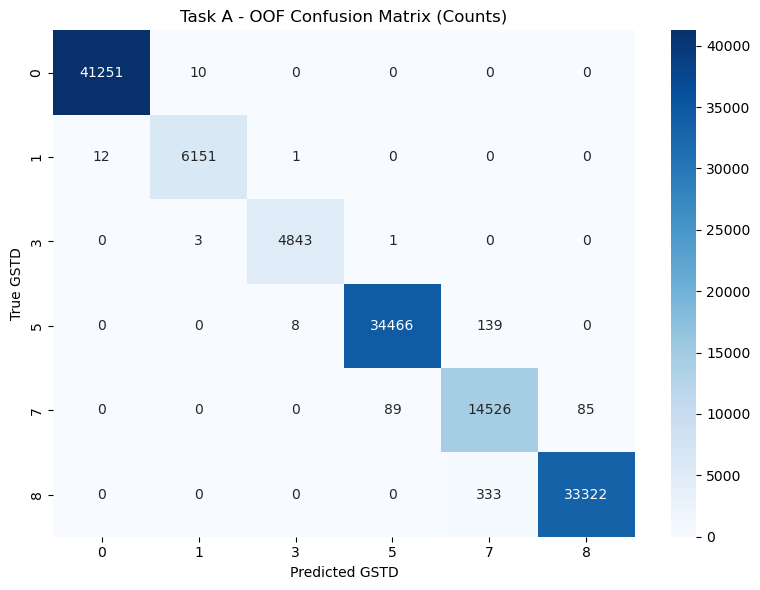

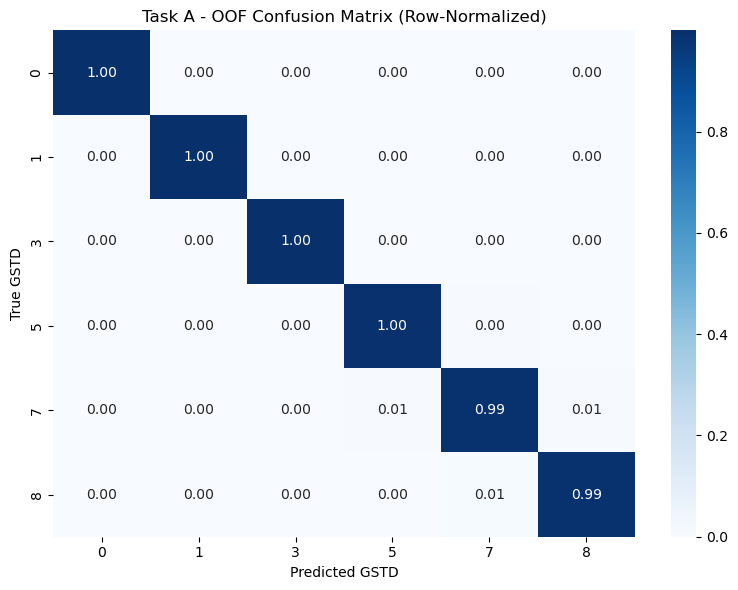


Per-class performance:


,precision,recall,f1-score,support
0,0.999709,0.999758,0.999733,41261
1,0.997891,0.997891,0.997891,6164
3,0.998145,0.999175,0.998660,4847
5,0.997396,0.995753,0.996574,34613
7,0.968529,0.988163,0.978248,14700
8,0.997456,0.990105,0.993767,33655



OOF prediction sample:


,RUNNO,GSTD,DATE,DAP,y_true,y_pred,proba_0,proba_1,proba_3,proba_5,proba_7,proba_8
0,1,0,2023-05-02,0,0,0,1.0,3.017386e-09,7.997349e-10,4.384685e-08,7.517177e-10,4.402294e-10
1,1,0,2023-05-03,1,0,0,1.0,1.186768e-09,7.343991e-10,3.621833e-08,5.792861e-10,4.220758e-10
2,1,0,2023-05-04,2,0,0,1.0,1.475269e-09,7.928285e-10,3.599974e-08,6.253746e-10,4.783387e-10
3,1,0,2023-05-05,3,0,0,1.0,1.823260e-09,7.748123e-10,3.599974e-08,5.777435e-10,3.883065e-10
4,1,0,2023-05-06,4,0,0,1.0,1.658814e-09,1.135900e-09,2.407117e-08,6.318097e-10,3.873679e-10



Saved object: taskA_oof


In [2]:
# ============================================================
# SECTION A2: STRICT MULTICLASS LIGHTGBM BASELINE
# GroupKFold by RUNNO for honest evaluation
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupKFold
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from lightgbm import LGBMClassifier

# Set up grouped cross-validation so each fold holds out full runs.
n_splits = 5
gkf = GroupKFold(n_splits=n_splits)

classes = np.sort(y.unique())
class_names = [str(c) for c in classes]

oof_pred = np.zeros(len(y), dtype=int)
oof_proba = np.zeros((len(y), len(classes)), dtype=float)

fold_rows = []

# Train and validate one fold at a time.
for fold, (train_idx, valid_idx) in enumerate(gkf.split(X, y, groups=groups), start=1):
    print("=" * 70)
    print(f"Fold {fold}/{n_splits}")
    
    X_train, X_valid = X.iloc[train_idx], X.iloc[valid_idx]
    y_train, y_valid = y.iloc[train_idx], y.iloc[valid_idx]

    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("clf", LGBMClassifier(
            objective="multiclass",
            num_class=len(classes),
            n_estimators=300,
            learning_rate=0.05,
            num_leaves=31,
            max_depth=-1,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=42,
            class_weight="balanced",
            n_jobs=-1,
            verbosity=-1
        ))
    ])

    model.fit(X_train, y_train)

    valid_pred = model.predict(X_valid)
    valid_proba = model.predict_proba(X_valid)

    oof_pred[valid_idx] = valid_pred
    oof_proba[valid_idx] = valid_proba

    fold_acc = accuracy_score(y_valid, valid_pred)
    fold_bal_acc = balanced_accuracy_score(y_valid, valid_pred)
    fold_macro_f1 = f1_score(y_valid, valid_pred, average="macro")
    fold_weighted_f1 = f1_score(y_valid, valid_pred, average="weighted")

    fold_rows.append({
        "fold": fold,
        "n_train": len(train_idx),
        "n_valid": len(valid_idx),
        "accuracy": fold_acc,
        "balanced_accuracy": fold_bal_acc,
        "macro_f1": fold_macro_f1,
        "weighted_f1": fold_weighted_f1
    })

    print(f"Accuracy           : {fold_acc:.4f}")
    print(f"Balanced Accuracy  : {fold_bal_acc:.4f}")
    print(f"Macro F1           : {fold_macro_f1:.4f}")
    print(f"Weighted F1        : {fold_weighted_f1:.4f}")

# Fold summary
fold_results = pd.DataFrame(fold_rows)

print("\n" + "=" * 70)
print("FOLD-LEVEL RESULTS")
display(fold_results)

print("\nMean CV Metrics:")
print(fold_results[["accuracy", "balanced_accuracy", "macro_f1", "weighted_f1"]].mean().round(4))

# Overall OOF results
overall_acc = accuracy_score(y, oof_pred)
overall_bal_acc = balanced_accuracy_score(y, oof_pred)
overall_macro_f1 = f1_score(y, oof_pred, average="macro")
overall_weighted_f1 = f1_score(y, oof_pred, average="weighted")

print("\n" + "=" * 70)
print("OVERALL OUT-OF-FOLD RESULTS")
print(f"Accuracy           : {overall_acc:.4f}")
print(f"Balanced Accuracy  : {overall_bal_acc:.4f}")
print(f"Macro F1           : {overall_macro_f1:.4f}")
print(f"Weighted F1        : {overall_weighted_f1:.4f}")

# Classification report
report = classification_report(
    y,
    oof_pred,
    labels=classes,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).T
print("\nClassification Report (OOF):")
display(report_df)

# Plot the confusion matrix so we can see which stages are being mixed up. (counts)
cm = confusion_matrix(y, oof_pred, labels=classes)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Task A - OOF Confusion Matrix (Counts)")
plt.xlabel("Predicted GSTD")
plt.ylabel("True GSTD")
plt.tight_layout()
plt.show()

# Plot the confusion matrix so we can see which stages are being mixed up. (row-normalized)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_norm,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Task A - OOF Confusion Matrix (Row-Normalized)")
plt.xlabel("Predicted GSTD")
plt.ylabel("True GSTD")
plt.tight_layout()
plt.show()

# Per-class metrics table
per_class_df = report_df.loc[class_names, ["precision", "recall", "f1-score", "support"]].copy()
per_class_df["support"] = per_class_df["support"].astype(int)

print("\nPer-class performance:")
display(per_class_df)

# Save these tables as notebook objects for later export or reuse. OOF predictions for later analysis
taskA_oof = df[[group_col, target_col]].copy()
if "DATE" in df.columns:
    taskA_oof["DATE"] = df["DATE"]
if "DAP" in df.columns:
    taskA_oof["DAP"] = df["DAP"]

taskA_oof["y_true"] = y.values
taskA_oof["y_pred"] = oof_pred

for i, cls in enumerate(classes):
    taskA_oof[f"proba_{cls}"] = oof_proba[:, i]

print("\nOOF prediction sample:")
display(taskA_oof.head())

print("\nSaved object: taskA_oof")

Top 30 features by gain importance:


,feature,gain_importance,split_importance,gain_pct
0,L#SD,1.610146e+06,3863,32.301034
1,SH%D,8.845477e+05,1088,17.744854
2,GWGD,4.709398e+05,1009,9.447492
3,G#AD,2.886216e+05,285,5.790019
4,RDPD,1.940038e+05,2732,3.891898
5,LWAD,1.340887e+05,686,2.689944
6,HIAD,1.294265e+05,1037,2.596417
7,CHTD,1.262436e+05,912,2.532564
8,SNW0C,1.198407e+05,1381,2.404116
9,LN%D,1.186563e+05,518,2.380356


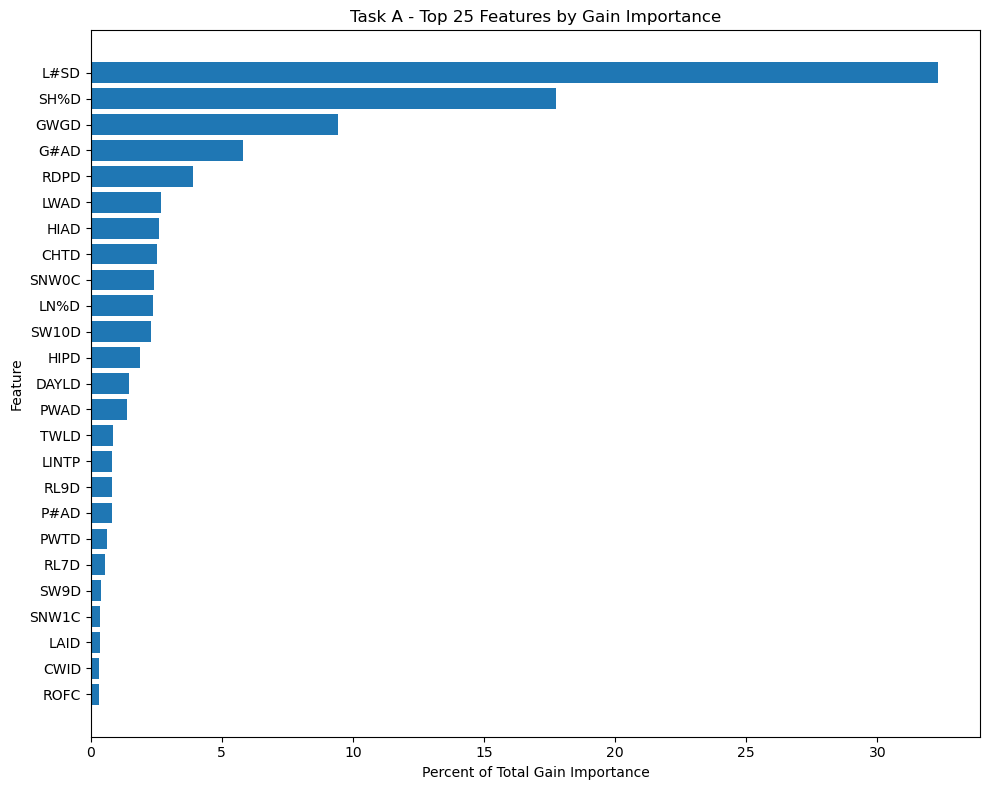


Top 40 features with proxy flags:


,feature,gain_importance,split_importance,gain_pct,proxy_flag
0,L#SD,1.610146e+06,3863,32.301034,
1,SH%D,8.845477e+05,1088,17.744854,sh
2,GWGD,4.709398e+05,1009,9.447492,
3,G#AD,2.886216e+05,285,5.790019,
4,RDPD,1.940038e+05,2732,3.891898,
5,LWAD,1.340887e+05,686,2.689944,
6,HIAD,1.294265e+05,1037,2.596417,hiad
7,CHTD,1.262436e+05,912,2.532564,
8,SNW0C,1.198407e+05,1381,2.404116,
9,LN%D,1.186563e+05,518,2.380356,ln



Saved object: taskA_feature_importance


In [3]:
# ============================================================
# SECTION A3: FEATURE IMPORTANCE + PROXY AUDIT
# Train one full strict model and inspect top drivers
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from lightgbm import LGBMClassifier

# Fit one full model only for interpretation of feature importance.
imputer = SimpleImputer(strategy="median")
X_imp = imputer.fit_transform(X)

full_model = LGBMClassifier(
    objective="multiclass",
    num_class=len(classes),
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1,
    verbosity=-1
)

full_model.fit(X_imp, y)

# Use LightGBM gain importance to see which variables are driving the model.
booster = full_model.booster_
gain_importance = booster.feature_importance(importance_type="gain")
split_importance = booster.feature_importance(importance_type="split")

fi_df = pd.DataFrame({
    "feature": feature_cols,
    "gain_importance": gain_importance,
    "split_importance": split_importance
})

fi_df["gain_pct"] = 100 * fi_df["gain_importance"] / fi_df["gain_importance"].sum()
fi_df = fi_df.sort_values("gain_importance", ascending=False).reset_index(drop=True)

print("Top 30 features by gain importance:")
display(fi_df.head(30))

# Plot top 25 by gain
top_n = 25
plot_df = fi_df.head(top_n).sort_values("gain_pct", ascending=True)

plt.figure(figsize=(10, 8))
plt.barh(plot_df["feature"], plot_df["gain_pct"])
plt.xlabel("Percent of Total Gain Importance")
plt.ylabel("Feature")
plt.title("Task A - Top 25 Features by Gain Importance")
plt.tight_layout()
plt.show()

# Flag possible proxy features
proxy_keywords = [
    "stage", "gst", "dap", "day", "date", "wdate", "das",
    "lai", "cwad", "gwad", "vwad", "hiad", "rwad", "swad",
    "ln", "sh", "pod", "boll", "leaf", "stem", "root"
]

proxy_flags = []
for f in fi_df["feature"]:
    f_lower = f.lower()
    matched = [kw for kw in proxy_keywords if kw in f_lower]
    proxy_flags.append(", ".join(matched) if matched else "")

fi_df["proxy_flag"] = proxy_flags

print("\nTop 40 features with proxy flags:")
display(fi_df.head(40))

# Save these tables as notebook objects for later export or reuse. for later use
taskA_feature_importance = fi_df.copy()
print("\nSaved object: taskA_feature_importance")

Proxy-like features being removed:
['L#SD', 'SH%D', 'GWGD', 'G#AD', 'RDPD', 'LWAD', 'HIAD', 'CHTD', 'LN%D', 'LAID', 'VWAD', 'RWAD', 'PWAD']

Number removed: 13

Original feature count: 131
Reduced feature count : 118
Reduced Model Fold 1/5
Accuracy           : 0.9938
Balanced Accuracy  : 0.9928
Macro F1           : 0.9921
Weighted F1        : 0.9938
Reduced Model Fold 2/5
Accuracy           : 0.9941
Balanced Accuracy  : 0.9943
Macro F1           : 0.9931
Weighted F1        : 0.9941
Reduced Model Fold 3/5
Accuracy           : 0.9945
Balanced Accuracy  : 0.9948
Macro F1           : 0.9934
Weighted F1        : 0.9945
Reduced Model Fold 4/5
Accuracy           : 0.9939
Balanced Accuracy  : 0.9934
Macro F1           : 0.9922
Weighted F1        : 0.9939
Reduced Model Fold 5/5
Accuracy           : 0.9935
Balanced Accuracy  : 0.9926
Macro F1           : 0.9913
Weighted F1        : 0.9935

REDUCED MODEL FOLD-LEVEL RESULTS


,fold,accuracy,balanced_accuracy,macro_f1,weighted_f1
0,1,0.993789,0.992791,0.992107,0.993811
1,2,0.994085,0.994289,0.993124,0.994105
2,3,0.994491,0.994794,0.993427,0.994513
3,4,0.993863,0.993373,0.992167,0.993886
4,5,0.993493,0.992629,0.991265,0.993519



Reduced model mean CV metrics:
accuracy             0.9939
balanced_accuracy    0.9936
macro_f1             0.9924
weighted_f1          0.9940
dtype: float64

REDUCED MODEL OVERALL OOF RESULTS
Accuracy           : 0.9939
Balanced Accuracy  : 0.9936
Macro F1           : 0.9924
Weighted F1        : 0.9940

Reduced Model Classification Report (OOF):


,precision,recall,f1-score,support
0,0.999636,0.999540,0.999588,41261.000000
1,0.994814,0.995782,0.995298,6164.000000
3,0.995261,0.996493,0.995876,4847.000000
5,0.996093,0.994308,0.995200,34613.000000
7,0.964393,0.985714,0.974937,14700.000000
8,0.997634,0.989600,0.993601,33655.000000
accuracy,0.993944,0.993944,0.993944,0.993944
macro avg,0.991305,0.993573,0.992417,135240.000000
weighted avg,0.994024,0.993944,0.993967,135240.000000


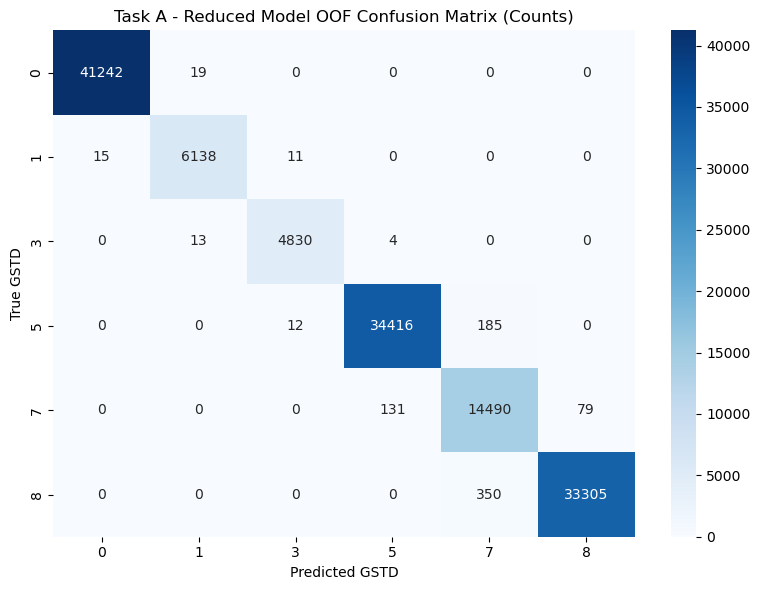

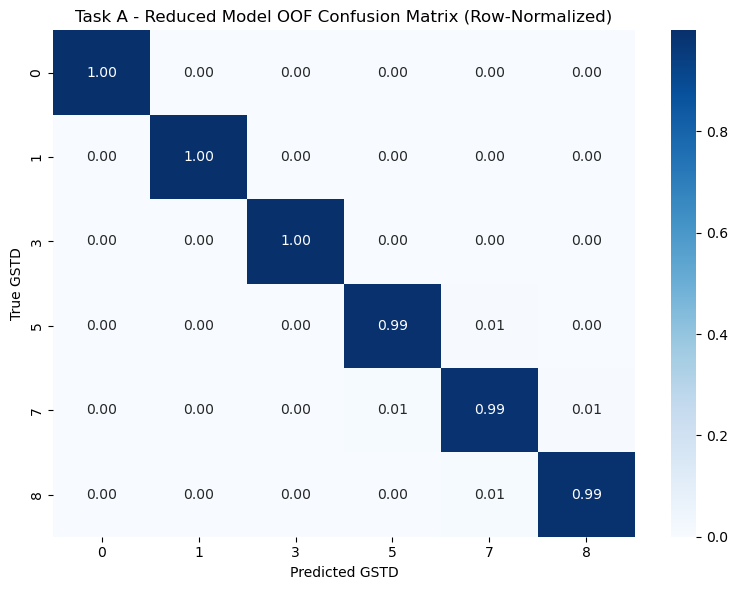


Strict vs Proxy-Reduced Comparison:


,metric,strict_full_model,proxy_reduced_model,absolute_drop
0,accuracy,0.994965,0.993944,0.001020
1,balanced_accuracy,0.995141,0.993573,0.001568
2,macro_f1,0.994145,0.992417,0.001729
3,weighted_f1,0.994982,0.993967,0.001015



Saved objects:
- taskA_reduced_feature_cols
- taskA_reduced_results
- taskA_reduced_report


In [4]:
# ============================================================
# SECTION A4: PROXY-REDUCED ROBUSTNESS TEST
# Remove the strongest stage-like features and re-evaluate
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupKFold
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from lightgbm import LGBMClassifier

# Remove the features that look most like direct stage or crop-state shortcuts.
# This list comes from the earlier importance audit.
drop_proxy_features = [
    "L#SD",
    "SH%D",
    "GWGD",
    "G#AD",
    "RDPD",
    "LWAD",
    "HIAD",
    "CHTD",
    "LN%D",
    "LAID",
    "VWAD",
    "RWAD",
    "PWAD"
]

drop_proxy_features = [f for f in drop_proxy_features if f in feature_cols]

print("Proxy-like features being removed:")
print(drop_proxy_features)
print(f"\nNumber removed: {len(drop_proxy_features)}")

# Build reduced feature matrix
reduced_feature_cols = [f for f in feature_cols if f not in drop_proxy_features]

X_reduced = df[reduced_feature_cols].copy()

print(f"\nOriginal feature count: {len(feature_cols)}")
print(f"Reduced feature count : {len(reduced_feature_cols)}")

# GroupKFold setup
n_splits = 5
gkf = GroupKFold(n_splits=n_splits)

classes = np.sort(y.unique())
class_names = [str(c) for c in classes]

oof_pred_red = np.zeros(len(y), dtype=int)
oof_proba_red = np.zeros((len(y), len(classes)), dtype=float)

fold_rows_red = []

# Train and validate one fold at a time.
for fold, (train_idx, valid_idx) in enumerate(gkf.split(X_reduced, y, groups=groups), start=1):
    print("=" * 70)
    print(f"Reduced Model Fold {fold}/{n_splits}")

    X_train, X_valid = X_reduced.iloc[train_idx], X_reduced.iloc[valid_idx]
    y_train, y_valid = y.iloc[train_idx], y.iloc[valid_idx]

    model_red = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("clf", LGBMClassifier(
            objective="multiclass",
            num_class=len(classes),
            n_estimators=300,
            learning_rate=0.05,
            num_leaves=31,
            max_depth=-1,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=42,
            class_weight="balanced",
            n_jobs=-1,
            verbosity=-1
        ))
    ])

    model_red.fit(X_train, y_train)

    valid_pred = model_red.predict(X_valid)
    valid_proba = model_red.predict_proba(X_valid)

    oof_pred_red[valid_idx] = valid_pred
    oof_proba_red[valid_idx] = valid_proba

    fold_acc = accuracy_score(y_valid, valid_pred)
    fold_bal_acc = balanced_accuracy_score(y_valid, valid_pred)
    fold_macro_f1 = f1_score(y_valid, valid_pred, average="macro")
    fold_weighted_f1 = f1_score(y_valid, valid_pred, average="weighted")

    fold_rows_red.append({
        "fold": fold,
        "accuracy": fold_acc,
        "balanced_accuracy": fold_bal_acc,
        "macro_f1": fold_macro_f1,
        "weighted_f1": fold_weighted_f1
    })

    print(f"Accuracy           : {fold_acc:.4f}")
    print(f"Balanced Accuracy  : {fold_bal_acc:.4f}")
    print(f"Macro F1           : {fold_macro_f1:.4f}")
    print(f"Weighted F1        : {fold_weighted_f1:.4f}")

# Fold summary
reduced_results = pd.DataFrame(fold_rows_red)

print("\n" + "=" * 70)
print("REDUCED MODEL FOLD-LEVEL RESULTS")
display(reduced_results)

print("\nReduced model mean CV metrics:")
print(reduced_results[["accuracy", "balanced_accuracy", "macro_f1", "weighted_f1"]].mean().round(4))

# Overall reduced OOF results
overall_acc_red = accuracy_score(y, oof_pred_red)
overall_bal_acc_red = balanced_accuracy_score(y, oof_pred_red)
overall_macro_f1_red = f1_score(y, oof_pred_red, average="macro")
overall_weighted_f1_red = f1_score(y, oof_pred_red, average="weighted")

print("\n" + "=" * 70)
print("REDUCED MODEL OVERALL OOF RESULTS")
print(f"Accuracy           : {overall_acc_red:.4f}")
print(f"Balanced Accuracy  : {overall_bal_acc_red:.4f}")
print(f"Macro F1           : {overall_macro_f1_red:.4f}")
print(f"Weighted F1        : {overall_weighted_f1_red:.4f}")

# Classification report
report_red = classification_report(
    y,
    oof_pred_red,
    labels=classes,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_red_df = pd.DataFrame(report_red).T
print("\nReduced Model Classification Report (OOF):")
display(report_red_df)

# Plot the confusion matrix so we can see which stages are being mixed up.
cm_red = confusion_matrix(y, oof_pred_red, labels=classes)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_red,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Task A - Reduced Model OOF Confusion Matrix (Counts)")
plt.xlabel("Predicted GSTD")
plt.ylabel("True GSTD")
plt.tight_layout()
plt.show()

cm_red_norm = cm_red.astype(float) / cm_red.sum(axis=1, keepdims=True)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_red_norm,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Task A - Reduced Model OOF Confusion Matrix (Row-Normalized)")
plt.xlabel("Predicted GSTD")
plt.ylabel("True GSTD")
plt.tight_layout()
plt.show()

# Side-by-side comparison
comparison_df = pd.DataFrame({
    "metric": ["accuracy", "balanced_accuracy", "macro_f1", "weighted_f1"],
    "strict_full_model": [
        overall_acc,
        overall_bal_acc,
        overall_macro_f1,
        overall_weighted_f1
    ],
    "proxy_reduced_model": [
        overall_acc_red,
        overall_bal_acc_red,
        overall_macro_f1_red,
        overall_weighted_f1_red
    ]
})

comparison_df["absolute_drop"] = (
    comparison_df["strict_full_model"] - comparison_df["proxy_reduced_model"]
)

print("\nStrict vs Proxy-Reduced Comparison:")
display(comparison_df)

# Save these tables as notebook objects for later export or reuse. reduced outputs
taskA_reduced_feature_cols = reduced_feature_cols
taskA_reduced_results = reduced_results.copy()
taskA_reduced_report = report_red_df.copy()

print("\nSaved objects:")
print("- taskA_reduced_feature_cols")
print("- taskA_reduced_results")
print("- taskA_reduced_report")

Practical feature count: 46

Practical features:
['CO2D', 'DAYLD', 'DRNC', 'LN%D', 'NH10', 'NH1D', 'NH2D', 'NH3D', 'NH4D', 'NH5D', 'NH6D', 'NH7D', 'NH8D', 'NH9D', 'NI10', 'NI1D', 'NI2D', 'NI3D', 'NI4D', 'NI5D', 'NI6D', 'NI7D', 'NI8D', 'NI9D', 'NUCM', 'PREC', 'ROFC', 'SNW0C', 'SNW1C', 'SRAD', 'SW10D', 'SW1D', 'SW2D', 'SW3D', 'SW4D', 'SW5D', 'SW6D', 'SW7D', 'SW8D', 'SW9D', 'SWTD', 'SWXD', 'TMND', 'TMXD', 'VPD', 'VPDF']
Practical Model Fold 1/5
Practical Model Fold 2/5
Practical Model Fold 3/5
Practical Model Fold 4/5
Practical Model Fold 5/5

PRACTICAL MODEL FOLD RESULTS


,fold,accuracy,balanced_accuracy,macro_f1,weighted_f1
0,1,0.987060,0.984536,0.981741,0.987143
1,2,0.986136,0.985669,0.980437,0.986259
2,3,0.988169,0.988556,0.983246,0.988265
3,4,0.987578,0.987992,0.982727,0.987680
4,5,0.987947,0.986840,0.981907,0.988022



PRACTICAL MODEL OVERALL OOF RESULTS
Accuracy           : 0.9874
Balanced Accuracy  : 0.9867
Macro F1           : 0.9820
Weighted F1        : 0.9875

Practical Model Classification Report (OOF):


,precision,recall,f1-score,support
0,0.999563,0.998764,0.999164,41261.000000
1,0.988176,0.989779,0.988977,6164.000000
3,0.954853,0.990510,0.972354,4847.000000
5,0.994361,0.983186,0.988742,34613.000000
7,0.934080,0.976463,0.954801,14700.000000
8,0.994491,0.981607,0.988007,33655.000000
accuracy,0.987378,0.987378,0.987378,0.987378
macro avg,0.977587,0.986718,0.982007,135240.000000
weighted avg,0.987730,0.987378,0.987473,135240.000000


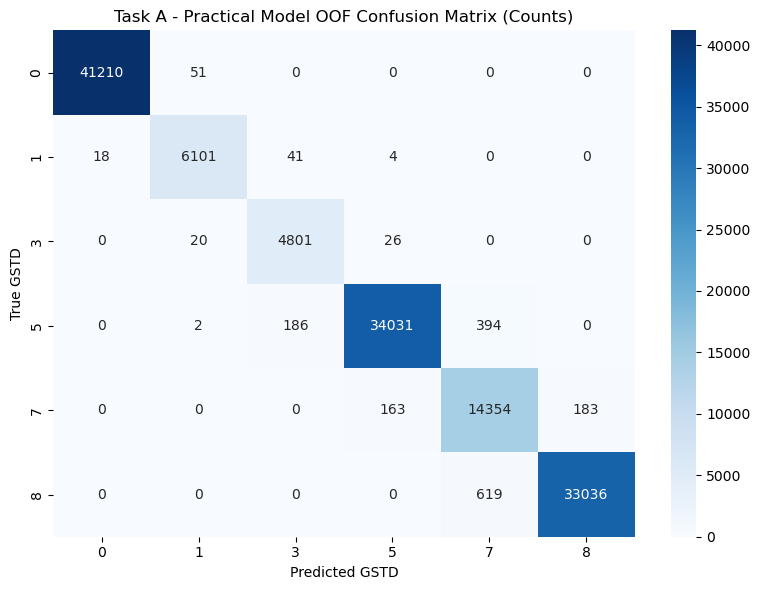

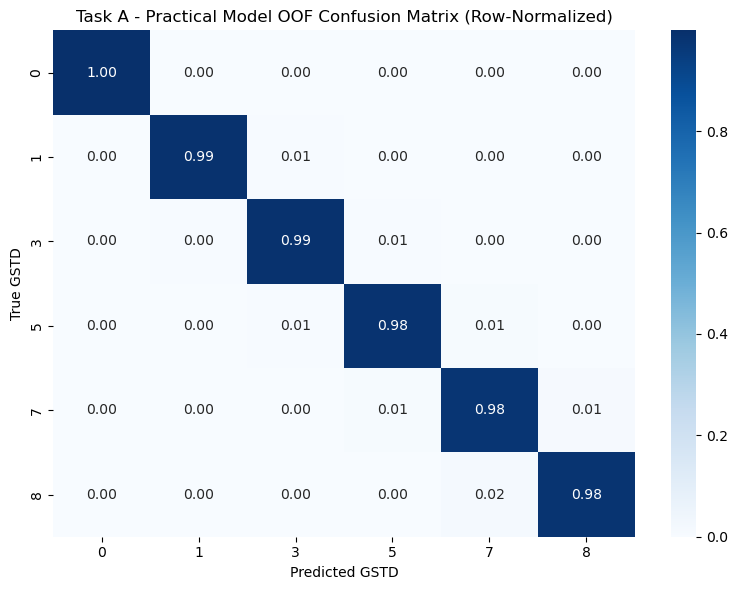


Three-way comparison:


,metric,strict_full_model,proxy_reduced_model,practical_model
0,accuracy,0.994965,0.993944,0.987378
1,balanced_accuracy,0.995141,0.993573,0.986718
2,macro_f1,0.994145,0.992417,0.982007
3,weighted_f1,0.994982,0.993967,0.987473


In [5]:
# ============================================================
# SECTION A5: PRACTICAL-FEATURE TASK A MODEL
# Restrict to more operationally realistic variables
# ============================================================

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupKFold
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from lightgbm import LGBMClassifier

# Keep variables that are more realistic for a client-facing monitoring setup.
# These are meant to avoid relying too heavily on direct plant morphology variables.
# Exclude highly stage-like plant morphology variables
practical_keep_patterns = [
    r"^TMAX", r"^TMIN", r"^TMXD", r"^TMND", r"^SRAD", r"^VPD", r"^PREC", r"^DAYLD",
    r"^SW\d+", r"^SWXD", r"^SWTD", r"^SNW", r"^ROFC", r"^DRN", r"^RAIN",
    r"^NI\d+", r"^NH\d+", r"^NO3", r"^NLAB", r"^NUCM", r"^NUPC", r"^LNTP", r"^LN%D",
    r"^CO2D"
]

# High-risk plant / morphology / direct state-like patterns to exclude
practical_exclude_patterns = [
    r"^LAI", r"^LAID",
    r"^GW", r"^CW", r"^VW", r"^RW", r"^PW", r"^LW",
    r"^HI", r"^CHT", r"^RDPD", r"^L#",
    r"^G#",
    r"^SH%", r"^P#",
]

def matches_any_pattern(col, patterns):
    return any(re.search(p, col) for p in patterns)

practical_feature_cols = []
for col in feature_cols:
    keep_ok = matches_any_pattern(col, practical_keep_patterns)
    exclude_bad = matches_any_pattern(col, practical_exclude_patterns)
    if keep_ok and not exclude_bad:
        practical_feature_cols.append(col)

practical_feature_cols = sorted(list(set(practical_feature_cols)))

print("Practical feature count:", len(practical_feature_cols))
print("\nPractical features:")
print(practical_feature_cols)

X_practical = df[practical_feature_cols].copy()

# GroupKFold setup
n_splits = 5
gkf = GroupKFold(n_splits=n_splits)

classes = np.sort(y.unique())
class_names = [str(c) for c in classes]

oof_pred_prac = np.zeros(len(y), dtype=int)
fold_rows_prac = []

# Train and validate one fold at a time.
for fold, (train_idx, valid_idx) in enumerate(gkf.split(X_practical, y, groups=groups), start=1):
    print("=" * 70)
    print(f"Practical Model Fold {fold}/{n_splits}")

    X_train, X_valid = X_practical.iloc[train_idx], X_practical.iloc[valid_idx]
    y_train, y_valid = y.iloc[train_idx], y.iloc[valid_idx]

    model_prac = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("clf", LGBMClassifier(
            objective="multiclass",
            num_class=len(classes),
            n_estimators=300,
            learning_rate=0.05,
            num_leaves=31,
            max_depth=-1,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=42,
            class_weight="balanced",
            n_jobs=-1,
            verbosity=-1
        ))
    ])

    model_prac.fit(X_train, y_train)
    valid_pred = model_prac.predict(X_valid)

    oof_pred_prac[valid_idx] = valid_pred

    fold_rows_prac.append({
        "fold": fold,
        "accuracy": accuracy_score(y_valid, valid_pred),
        "balanced_accuracy": balanced_accuracy_score(y_valid, valid_pred),
        "macro_f1": f1_score(y_valid, valid_pred, average="macro"),
        "weighted_f1": f1_score(y_valid, valid_pred, average="weighted")
    })

practical_results = pd.DataFrame(fold_rows_prac)

print("\nPRACTICAL MODEL FOLD RESULTS")
display(practical_results)

overall_acc_prac = accuracy_score(y, oof_pred_prac)
overall_bal_acc_prac = balanced_accuracy_score(y, oof_pred_prac)
overall_macro_f1_prac = f1_score(y, oof_pred_prac, average="macro")
overall_weighted_f1_prac = f1_score(y, oof_pred_prac, average="weighted")

print("\nPRACTICAL MODEL OVERALL OOF RESULTS")
print(f"Accuracy           : {overall_acc_prac:.4f}")
print(f"Balanced Accuracy  : {overall_bal_acc_prac:.4f}")
print(f"Macro F1           : {overall_macro_f1_prac:.4f}")
print(f"Weighted F1        : {overall_weighted_f1_prac:.4f}")

report_prac = classification_report(
    y,
    oof_pred_prac,
    labels=classes,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)
report_prac_df = pd.DataFrame(report_prac).T

print("\nPractical Model Classification Report (OOF):")
display(report_prac_df)

cm_prac = confusion_matrix(y, oof_pred_prac, labels=classes)
cm_prac_norm = cm_prac.astype(float) / cm_prac.sum(axis=1, keepdims=True)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_prac,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Task A - Practical Model OOF Confusion Matrix (Counts)")
plt.xlabel("Predicted GSTD")
plt.ylabel("True GSTD")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_prac_norm,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Task A - Practical Model OOF Confusion Matrix (Row-Normalized)")
plt.xlabel("Predicted GSTD")
plt.ylabel("True GSTD")
plt.tight_layout()
plt.show()

comparison_3way = pd.DataFrame({
    "metric": ["accuracy", "balanced_accuracy", "macro_f1", "weighted_f1"],
    "strict_full_model": [overall_acc, overall_bal_acc, overall_macro_f1, overall_weighted_f1],
    "proxy_reduced_model": [overall_acc_red, overall_bal_acc_red, overall_macro_f1_red, overall_weighted_f1_red],
    "practical_model": [overall_acc_prac, overall_bal_acc_prac, overall_macro_f1_prac, overall_weighted_f1_prac]
})

print("\nThree-way comparison:")
display(comparison_3way)

## Task A Summary: Current Growth Stage Classification

For Task A, we evaluated current growth stage classification using three progressively stricter modeling setups under honest GroupKFold validation by `RUNNO`.

The **full strict model** used the broadest leakage-safe feature space and achieved near-perfect performance, with macro F1 above 0.99. To test whether this result was driven mainly by a small number of highly stage-indicative crop variables, we then built a **proxy-reduced model** that removed the most dominant stage-like features. Performance remained extremely high, with only a very small drop, showing that the classifier is learning from a broader physiological signal rather than from a few shortcut variables alone.

Finally, we built a **practical model** using a smaller set of more operationally realistic features such as weather, soil water, and nutrient-related variables. Although performance declined modestly, the model still achieved very strong results, with macro F1 around 0.98. Across all three versions, the main errors occurred between neighboring late-season stages, especially **5 vs 7** and **7 vs 8**, which is biologically plausible and much more acceptable than widespread confusion across distant stages.

Overall, these results suggest that current growth stage can be classified very accurately from the validated dataset, and that the signal remains strong even after removing high-risk proxy variables and restricting the model to a more practical feature subset.

Practical Model - Train vs Validation Gap by Fold


,fold,train_accuracy,valid_accuracy,gap_accuracy,train_balanced_accuracy,valid_balanced_accuracy,gap_balanced_accuracy,train_macro_f1,valid_macro_f1,gap_macro_f1,train_weighted_f1,valid_weighted_f1,gap_weighted_f1
0,1,0.998956,0.987060,0.011896,0.999294,0.984536,0.014758,0.998540,0.981741,0.016799,0.998957,0.987143,0.011814
1,2,0.998928,0.986136,0.012792,0.999278,0.985669,0.013609,0.998356,0.980437,0.017919,0.998929,0.986259,0.012670
2,3,0.998845,0.988169,0.010675,0.999222,0.988556,0.010666,0.998233,0.983246,0.014988,0.998846,0.988265,0.010581
3,4,0.998956,0.987578,0.011378,0.999303,0.987992,0.011311,0.998556,0.982727,0.015830,0.998957,0.987680,0.011277
4,5,0.998817,0.987947,0.010870,0.999194,0.986840,0.012354,0.998303,0.981907,0.016395,0.998819,0.988022,0.010797



Average generalization gaps:


,mean_gap
gap_accuracy,0.011522
gap_balanced_accuracy,0.012539
gap_macro_f1,0.016386
gap_weighted_f1,0.011428


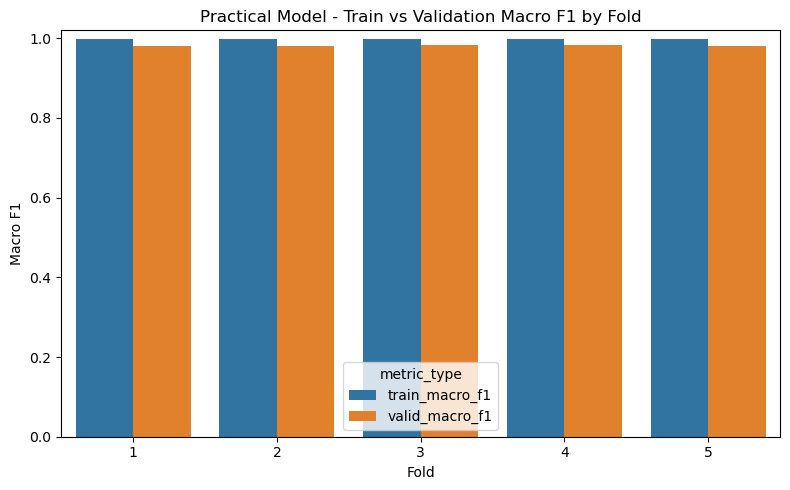


Mean Macro F1 Gap: 0.0164
Interpretation: modest train-validation gap; some overfitting may exist, but generalization still looks strong.


In [6]:
# ============================================================
# SECTION A6: OVERFITTING CHECK VIA TRAIN VS VALIDATION GAP
# Compare train and validation metrics in GroupKFold
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupKFold
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from lightgbm import LGBMClassifier

# Pick the feature set we want to check for train-vs-validation gaps.
# Useful options while reviewing the notebook:
#   X                -> strict full model
#   X_reduced        -> proxy-reduced model
#   X_practical      -> practical model
X_overfit = X_practical.copy()
model_name = "Practical Model"

# GroupKFold setup
n_splits = 5
gkf = GroupKFold(n_splits=n_splits)

rows = []

for fold, (train_idx, valid_idx) in enumerate(gkf.split(X_overfit, y, groups=groups), start=1):
    X_train, X_valid = X_overfit.iloc[train_idx], X_overfit.iloc[valid_idx]
    y_train, y_valid = y.iloc[train_idx], y.iloc[valid_idx]

    pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("clf", LGBMClassifier(
            objective="multiclass",
            num_class=len(np.sort(y.unique())),
            n_estimators=300,
            learning_rate=0.05,
            num_leaves=31,
            max_depth=-1,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=42,
            class_weight="balanced",
            n_jobs=-1,
            verbosity=-1
        ))
    ])

    pipe.fit(X_train, y_train)

    pred_train = pipe.predict(X_train)
    pred_valid = pipe.predict(X_valid)

    train_acc = accuracy_score(y_train, pred_train)
    valid_acc = accuracy_score(y_valid, pred_valid)

    train_bal_acc = balanced_accuracy_score(y_train, pred_train)
    valid_bal_acc = balanced_accuracy_score(y_valid, pred_valid)

    train_macro_f1 = f1_score(y_train, pred_train, average="macro")
    valid_macro_f1 = f1_score(y_valid, pred_valid, average="macro")

    train_weighted_f1 = f1_score(y_train, pred_train, average="weighted")
    valid_weighted_f1 = f1_score(y_valid, pred_valid, average="weighted")

    rows.append({
        "fold": fold,
        "train_accuracy": train_acc,
        "valid_accuracy": valid_acc,
        "gap_accuracy": train_acc - valid_acc,
        "train_balanced_accuracy": train_bal_acc,
        "valid_balanced_accuracy": valid_bal_acc,
        "gap_balanced_accuracy": train_bal_acc - valid_bal_acc,
        "train_macro_f1": train_macro_f1,
        "valid_macro_f1": valid_macro_f1,
        "gap_macro_f1": train_macro_f1 - valid_macro_f1,
        "train_weighted_f1": train_weighted_f1,
        "valid_weighted_f1": valid_weighted_f1,
        "gap_weighted_f1": train_weighted_f1 - valid_weighted_f1
    })

overfit_df = pd.DataFrame(rows)

print(f"{model_name} - Train vs Validation Gap by Fold")
display(overfit_df)

summary_cols = [
    "gap_accuracy",
    "gap_balanced_accuracy",
    "gap_macro_f1",
    "gap_weighted_f1"
]

print("\nAverage generalization gaps:")
display(overfit_df[summary_cols].mean().to_frame("mean_gap"))

# Plot macro F1 train vs validation
plot_df = overfit_df[["fold", "train_macro_f1", "valid_macro_f1"]].melt(
    id_vars="fold",
    var_name="metric_type",
    value_name="score"
)

plt.figure(figsize=(8, 5))
sns.barplot(data=plot_df, x="fold", y="score", hue="metric_type")
plt.title(f"{model_name} - Train vs Validation Macro F1 by Fold")
plt.ylabel("Macro F1")
plt.xlabel("Fold")
plt.ylim(0.0, 1.02)
plt.tight_layout()
plt.show()

# Simple interpretation helper
mean_gap_macro_f1 = overfit_df["gap_macro_f1"].mean()

print(f"\nMean Macro F1 Gap: {mean_gap_macro_f1:.4f}")

if mean_gap_macro_f1 < 0.01:
    print("Interpretation: very small train-validation gap; little evidence of strong overfitting.")
elif mean_gap_macro_f1 < 0.03:
    print("Interpretation: modest train-validation gap; some overfitting may exist, but generalization still looks strong.")
else:
    print("Interpretation: noticeable train-validation gap; investigate overfitting more carefully.")

Unique treatments: 35
Treatment counts:


,rows
TRTNO,
1,3864
2,3864
3,3864
4,3864
5,3864
6,3864
7,3864
8,3864
9,3864


Treatment-Held-Out Fold 1/5
Train treatments (28): [1, 3, 4, 5, 6, 8, 9, 10, 11, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 24, 25, 26, 27, 29, 30, 31, 32, 34]
Valid treatments (7): [2, 7, 12, 23, 28, 33, 35]
Accuracy           : 0.9789
Balanced Accuracy  : 0.9773
Macro F1           : 0.9713
Weighted F1        : 0.9791
Treatment-Held-Out Fold 2/5
Train treatments (28): [1, 2, 3, 4, 5, 7, 8, 10, 12, 13, 14, 15, 17, 18, 19, 20, 21, 23, 24, 25, 27, 28, 29, 30, 31, 33, 34, 35]
Valid treatments (7): [6, 9, 11, 16, 22, 26, 32]
Accuracy           : 0.9920
Balanced Accuracy  : 0.9927
Macro F1           : 0.9900
Weighted F1        : 0.9920
Treatment-Held-Out Fold 3/5
Train treatments (28): [1, 2, 3, 4, 6, 7, 8, 9, 11, 12, 13, 14, 16, 17, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 32, 33, 34, 35]
Valid treatments (7): [5, 10, 15, 18, 19, 21, 31]
Accuracy           : 0.9934
Balanced Accuracy  : 0.9944
Macro F1           : 0.9913
Weighted F1        : 0.9934
Treatment-Held-Out Fold 4/5
Train treatments (

,fold,n_train_rows,n_valid_rows,n_train_treatments,n_valid_treatments,accuracy,balanced_accuracy,macro_f1,weighted_f1
0,1,108192,27048,28,7,0.978889,0.977278,0.971296,0.979100
1,2,108192,27048,28,7,0.991977,0.992726,0.989985,0.992028
2,3,108192,27048,28,7,0.993382,0.994427,0.991306,0.993415
3,4,108192,27048,28,7,0.983067,0.983674,0.977002,0.983249
4,5,108192,27048,28,7,0.991940,0.993161,0.988848,0.991990



Mean treatment-held-out CV metrics:


,mean
accuracy,0.987851
balanced_accuracy,0.988253
macro_f1,0.983687
weighted_f1,0.987956



TREATMENT-HELD-OUT OVERALL OOF RESULTS
Accuracy           : 0.9879
Balanced Accuracy  : 0.9883
Macro F1           : 0.9837
Weighted F1        : 0.9879

Treatment-Held-Out Classification Report (OOF):


,precision,recall,f1-score,support
0,0.999830,0.998958,0.999394,41261.000000
1,0.991439,0.995782,0.993606,6164.000000
3,0.962622,0.993604,0.977868,4847.000000
5,0.992700,0.986075,0.989376,34613.000000
7,0.932714,0.976939,0.954314,14700.000000
8,0.996701,0.978547,0.987541,33655.000000
accuracy,0.987851,0.987851,0.987851,0.987851
macro avg,0.979334,0.988317,0.983683,135240.000000
weighted avg,0.988215,0.987851,0.987945,135240.000000


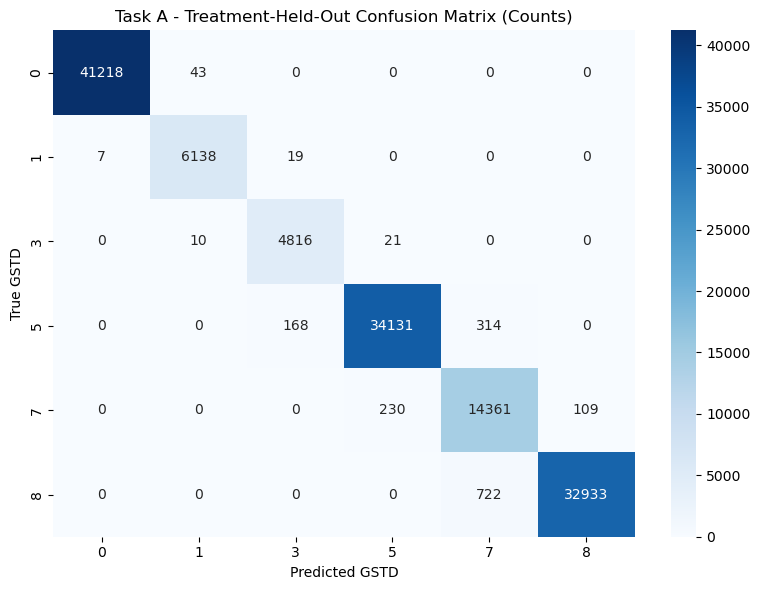

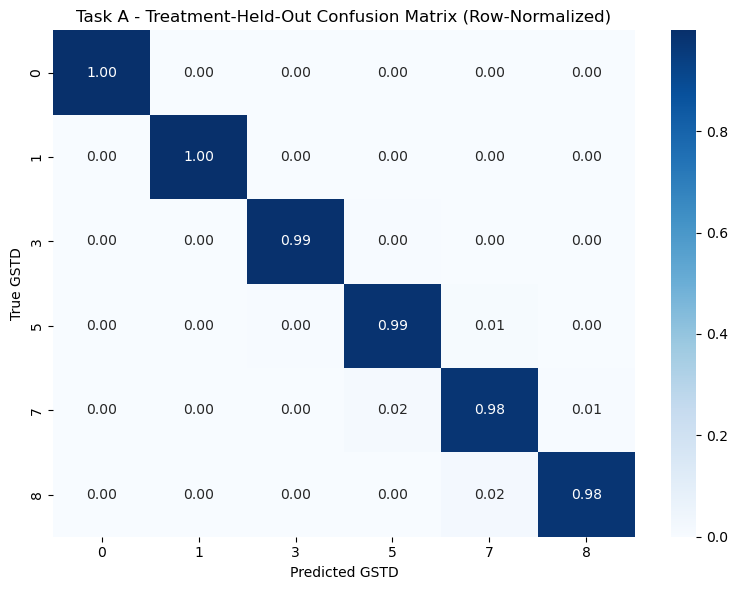


Four-way comparison:


,metric,strict_full_model_run_holdout,proxy_reduced_run_holdout,practical_run_holdout,practical_treatment_holdout,drop_vs_practical_run_holdout
0,accuracy,0.994965,0.993944,0.987378,0.987851,-0.000473
1,balanced_accuracy,0.995141,0.993573,0.986718,0.988317,-0.001599
2,macro_f1,0.994145,0.992417,0.982007,0.983683,-0.001676
3,weighted_f1,0.994982,0.993967,0.987473,0.987945,-0.000472



Saved objects:
- taskA_treatment_results
- taskA_treatment_report
- taskA_treatment_fold_map


In [7]:
# ============================================================
# SECTION A7: TREATMENT-HELD-OUT ROBUSTNESS TEST
# GroupKFold by TRTNO instead of RUNNO
# Uses the practical Task A feature set
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupKFold
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from lightgbm import LGBMClassifier

# Use the practical feature set here because it is the most relevant robustness test.
X_treat = X_practical.copy()
y_treat = y.copy()
treatment_groups = df["TRTNO"].copy()

print("Unique treatments:", treatment_groups.nunique())
print("Treatment counts:")
display(treatment_groups.value_counts().sort_index().to_frame("rows"))

# GroupKFold by treatment
n_splits = 5
gkf_treat = GroupKFold(n_splits=n_splits)

classes = np.sort(y_treat.unique())
class_names = [str(c) for c in classes]

oof_pred_treat = np.zeros(len(y_treat), dtype=int)
fold_rows_treat = []
fold_treatment_map = []

for fold, (train_idx, valid_idx) in enumerate(
    gkf_treat.split(X_treat, y_treat, groups=treatment_groups), start=1
):
    X_train, X_valid = X_treat.iloc[train_idx], X_treat.iloc[valid_idx]
    y_train, y_valid = y_treat.iloc[train_idx], y_treat.iloc[valid_idx]

    train_treatments = sorted(treatment_groups.iloc[train_idx].unique().tolist())
    valid_treatments = sorted(treatment_groups.iloc[valid_idx].unique().tolist())

    print("=" * 70)
    print(f"Treatment-Held-Out Fold {fold}/{n_splits}")
    print(f"Train treatments ({len(train_treatments)}): {train_treatments}")
    print(f"Valid treatments ({len(valid_treatments)}): {valid_treatments}")

    model_treat = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("clf", LGBMClassifier(
            objective="multiclass",
            num_class=len(classes),
            n_estimators=300,
            learning_rate=0.05,
            num_leaves=31,
            max_depth=-1,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=42,
            class_weight="balanced",
            n_jobs=-1,
            verbosity=-1
        ))
    ])

    model_treat.fit(X_train, y_train)
    valid_pred = model_treat.predict(X_valid)

    oof_pred_treat[valid_idx] = valid_pred

    fold_acc = accuracy_score(y_valid, valid_pred)
    fold_bal_acc = balanced_accuracy_score(y_valid, valid_pred)
    fold_macro_f1 = f1_score(y_valid, valid_pred, average="macro")
    fold_weighted_f1 = f1_score(y_valid, valid_pred, average="weighted")

    fold_rows_treat.append({
        "fold": fold,
        "n_train_rows": len(train_idx),
        "n_valid_rows": len(valid_idx),
        "n_train_treatments": len(train_treatments),
        "n_valid_treatments": len(valid_treatments),
        "accuracy": fold_acc,
        "balanced_accuracy": fold_bal_acc,
        "macro_f1": fold_macro_f1,
        "weighted_f1": fold_weighted_f1
    })

    fold_treatment_map.append({
        "fold": fold,
        "train_treatments": train_treatments,
        "valid_treatments": valid_treatments
    })

    print(f"Accuracy           : {fold_acc:.4f}")
    print(f"Balanced Accuracy  : {fold_bal_acc:.4f}")
    print(f"Macro F1           : {fold_macro_f1:.4f}")
    print(f"Weighted F1        : {fold_weighted_f1:.4f}")

# Fold summary
treatment_results = pd.DataFrame(fold_rows_treat)

print("\n" + "=" * 70)
print("TREATMENT-HELD-OUT FOLD RESULTS")
display(treatment_results)

print("\nMean treatment-held-out CV metrics:")
display(
    treatment_results[["accuracy", "balanced_accuracy", "macro_f1", "weighted_f1"]]
    .mean()
    .to_frame("mean")
)

# Overall OOF results
overall_acc_treat = accuracy_score(y_treat, oof_pred_treat)
overall_bal_acc_treat = balanced_accuracy_score(y_treat, oof_pred_treat)
overall_macro_f1_treat = f1_score(y_treat, oof_pred_treat, average="macro")
overall_weighted_f1_treat = f1_score(y_treat, oof_pred_treat, average="weighted")

print("\n" + "=" * 70)
print("TREATMENT-HELD-OUT OVERALL OOF RESULTS")
print(f"Accuracy           : {overall_acc_treat:.4f}")
print(f"Balanced Accuracy  : {overall_bal_acc_treat:.4f}")
print(f"Macro F1           : {overall_macro_f1_treat:.4f}")
print(f"Weighted F1        : {overall_weighted_f1_treat:.4f}")

# Classification report
report_treat = classification_report(
    y_treat,
    oof_pred_treat,
    labels=classes,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)
report_treat_df = pd.DataFrame(report_treat).T

print("\nTreatment-Held-Out Classification Report (OOF):")
display(report_treat_df)

# Confusion matrices
cm_treat = confusion_matrix(y_treat, oof_pred_treat, labels=classes)
cm_treat_norm = cm_treat.astype(float) / cm_treat.sum(axis=1, keepdims=True)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_treat,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Task A - Treatment-Held-Out Confusion Matrix (Counts)")
plt.xlabel("Predicted GSTD")
plt.ylabel("True GSTD")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_treat_norm,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Task A - Treatment-Held-Out Confusion Matrix (Row-Normalized)")
plt.xlabel("Predicted GSTD")
plt.ylabel("True GSTD")
plt.tight_layout()
plt.show()

# Compare against earlier Task A models
comparison_4way = pd.DataFrame({
    "metric": ["accuracy", "balanced_accuracy", "macro_f1", "weighted_f1"],
    "strict_full_model_run_holdout": [
        overall_acc,
        overall_bal_acc,
        overall_macro_f1,
        overall_weighted_f1
    ],
    "proxy_reduced_run_holdout": [
        overall_acc_red,
        overall_bal_acc_red,
        overall_macro_f1_red,
        overall_weighted_f1_red
    ],
    "practical_run_holdout": [
        overall_acc_prac,
        overall_bal_acc_prac,
        overall_macro_f1_prac,
        overall_weighted_f1_prac
    ],
    "practical_treatment_holdout": [
        overall_acc_treat,
        overall_bal_acc_treat,
        overall_macro_f1_treat,
        overall_weighted_f1_treat
    ]
})

comparison_4way["drop_vs_practical_run_holdout"] = (
    comparison_4way["practical_run_holdout"] - comparison_4way["practical_treatment_holdout"]
)

print("\nFour-way comparison:")
display(comparison_4way)

# Save these tables as notebook objects for later export or reuse. outputs
taskA_treatment_results = treatment_results.copy()
taskA_treatment_report = report_treat_df.copy()
taskA_treatment_fold_map = pd.DataFrame(fold_treatment_map)

print("\nSaved objects:")
print("- taskA_treatment_results")
print("- taskA_treatment_report")
print("- taskA_treatment_fold_map")

## Treatment-Held-Out Robustness Summary

To test whether the Task A classifier was relying on treatment-specific patterns, we performed an additional robustness evaluation in which entire treatments were held out during validation. This is a stricter test than holding out only unseen runs, because the model must generalize to management conditions it did not observe during training.

The results remained very strong under treatment-held-out validation, with performance essentially unchanged relative to the practical run-held-out model. This suggests that the classifier is learning a robust physiological signal for current growth stage rather than memorizing treatment-specific structure. As in earlier experiments, the main remaining errors were concentrated between neighboring later stages, especially **5 vs 7** and **7 vs 8**, which is biologically plausible.

Overall, this treatment-held-out test provides strong evidence that Task A generalizes well across both unseen runs and unseen treatment conditions.

Client-feasible feature set (6 variables):
['TMND', 'PREC', 'SRAD', 'TMXD', 'TAVD', 'NURTD']

Shape: (135240, 6)

Missingness by feature:


,missing_rate
TMND,0.0
PREC,0.0
SRAD,0.0
TMXD,0.0
TAVD,0.0
NURTD,0.0


Client-6 Model Fold 1/5
Accuracy           : 0.5419
Balanced Accuracy  : 0.6190
Macro F1           : 0.4822
Weighted F1        : 0.5671
Client-6 Model Fold 2/5
Accuracy           : 0.5372
Balanced Accuracy  : 0.6164
Macro F1           : 0.4777
Weighted F1        : 0.5614
Client-6 Model Fold 3/5
Accuracy           : 0.5350
Balanced Accuracy  : 0.6037
Macro F1           : 0.4754
Weighted F1        : 0.5629
Client-6 Model Fold 4/5
Accuracy           : 0.5408
Balanced Accuracy  : 0.6116
Macro F1           : 0.4797
Weighted F1        : 0.5681
Client-6 Model Fold 5/5
Accuracy           : 0.5443
Balanced Accuracy  : 0.6127
Macro F1           : 0.4837
Weighted F1        : 0.5725

CLIENT-6 MODEL FOLD RESULTS


,fold,accuracy,balanced_accuracy,macro_f1,weighted_f1
0,1,0.541888,0.618960,0.482184,0.567070
1,2,0.537156,0.616419,0.477693,0.561414
2,3,0.534975,0.603710,0.475423,0.562893
3,4,0.540779,0.611552,0.479656,0.568135
4,5,0.544329,0.612732,0.483713,0.572480



Client-6 mean CV metrics:


,mean
accuracy,0.539825
balanced_accuracy,0.612675
macro_f1,0.479734
weighted_f1,0.566398



CLIENT-6 OVERALL OOF RESULTS
Accuracy           : 0.5398
Balanced Accuracy  : 0.6127
Macro F1           : 0.4798
Weighted F1        : 0.5665

Client-6 Classification Report (OOF):


,precision,recall,f1-score,support
0,0.964374,0.654080,0.779482,41261.000000
1,0.221906,0.759247,0.343436,6164.000000
3,0.224886,0.863214,0.356814,4847.000000
5,0.611484,0.202756,0.304535,34613.000000
7,0.268412,0.535034,0.357484,14700.000000
8,0.831597,0.661744,0.737011,33655.000000
accuracy,0.539825,0.539825,0.539825,0.539825
macro avg,0.520443,0.612679,0.479794,135240.000000
weighted avg,0.705022,0.539825,0.566464,135240.000000


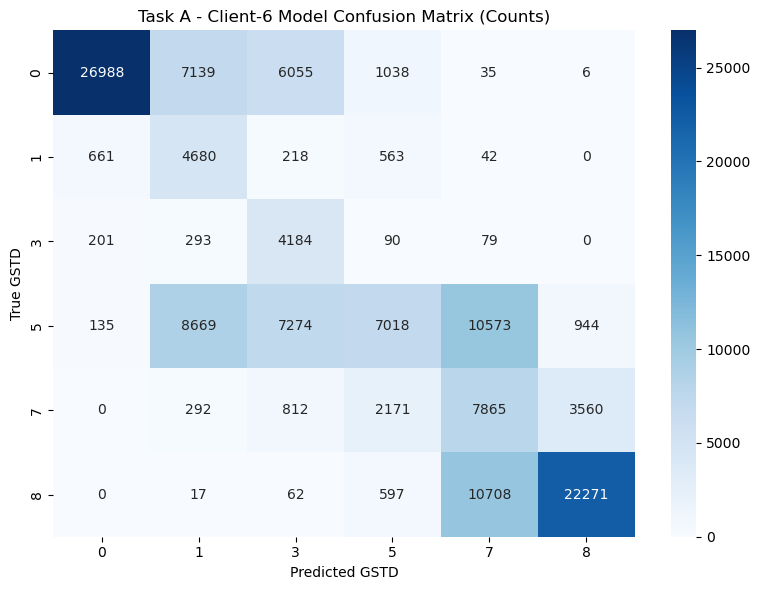

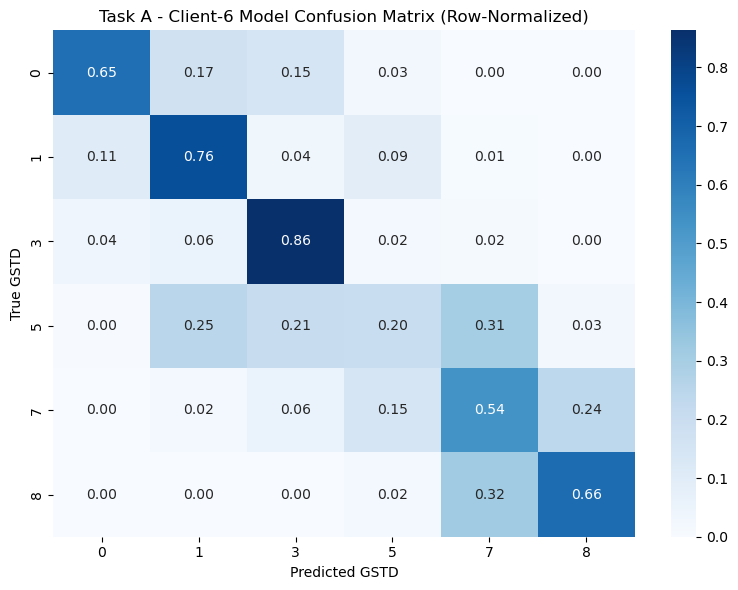


Five-way comparison:


,metric,strict_full_model_run_holdout,proxy_reduced_run_holdout,practical_run_holdout,practical_treatment_holdout,client6_run_holdout,drop_vs_practical_run_holdout
0,accuracy,0.994965,0.993944,0.987378,0.987851,0.539825,0.447552
1,balanced_accuracy,0.995141,0.993573,0.986718,0.988317,0.612679,0.374039
2,macro_f1,0.994145,0.992417,0.982007,0.983683,0.479794,0.502214
3,weighted_f1,0.994982,0.993967,0.987473,0.987945,0.566464,0.421009



Saved objects:
- taskA_client6_results
- taskA_client6_report


In [8]:
# ============================================================
# SECTION A8: TASK A USING TASK B CLIENT-FEASIBLE VARIABLES
# 6-feature feasibility-constrained current growth stage model
# Honest evaluation: GroupKFold by RUNNO
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupKFold
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from lightgbm import LGBMClassifier

# Reuse the same six feasible variables from Task B so the two tasks stay aligned.
client6_features = ["TMND", "PREC", "SRAD", "TMXD", "TAVD", "NURTD"]

missing_client6 = [c for c in client6_features if c not in df.columns]
if missing_client6:
    raise ValueError(f"These client-feasible columns are missing from df: {missing_client6}")

X_client6 = df[client6_features].copy()
y_client6 = y.copy()
groups_client6 = groups.copy()

print("Client-feasible feature set (6 variables):")
print(client6_features)
print("\nShape:", X_client6.shape)

print("\nMissingness by feature:")
display(X_client6.isna().mean().to_frame("missing_rate"))

# GroupKFold by RUNNO
n_splits = 5
gkf_client6 = GroupKFold(n_splits=n_splits)

classes = np.sort(y_client6.unique())
class_names = [str(c) for c in classes]

oof_pred_client6 = np.zeros(len(y_client6), dtype=int)
fold_rows_client6 = []

for fold, (train_idx, valid_idx) in enumerate(
    gkf_client6.split(X_client6, y_client6, groups=groups_client6), start=1
):
    print("=" * 70)
    print(f"Client-6 Model Fold {fold}/{n_splits}")

    X_train, X_valid = X_client6.iloc[train_idx], X_client6.iloc[valid_idx]
    y_train, y_valid = y_client6.iloc[train_idx], y_client6.iloc[valid_idx]

    model_client6 = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("clf", LGBMClassifier(
            objective="multiclass",
            num_class=len(classes),
            n_estimators=300,
            learning_rate=0.05,
            num_leaves=31,
            max_depth=-1,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=42,
            class_weight="balanced",
            n_jobs=-1,
            verbosity=-1
        ))
    ])

    model_client6.fit(X_train, y_train)
    valid_pred = model_client6.predict(X_valid)

    oof_pred_client6[valid_idx] = valid_pred

    fold_acc = accuracy_score(y_valid, valid_pred)
    fold_bal_acc = balanced_accuracy_score(y_valid, valid_pred)
    fold_macro_f1 = f1_score(y_valid, valid_pred, average="macro")
    fold_weighted_f1 = f1_score(y_valid, valid_pred, average="weighted")

    fold_rows_client6.append({
        "fold": fold,
        "accuracy": fold_acc,
        "balanced_accuracy": fold_bal_acc,
        "macro_f1": fold_macro_f1,
        "weighted_f1": fold_weighted_f1
    })

    print(f"Accuracy           : {fold_acc:.4f}")
    print(f"Balanced Accuracy  : {fold_bal_acc:.4f}")
    print(f"Macro F1           : {fold_macro_f1:.4f}")
    print(f"Weighted F1        : {fold_weighted_f1:.4f}")

# Fold summary
client6_results = pd.DataFrame(fold_rows_client6)

print("\n" + "=" * 70)
print("CLIENT-6 MODEL FOLD RESULTS")
display(client6_results)

print("\nClient-6 mean CV metrics:")
display(
    client6_results[["accuracy", "balanced_accuracy", "macro_f1", "weighted_f1"]]
    .mean()
    .to_frame("mean")
)

# Overall OOF results
overall_acc_client6 = accuracy_score(y_client6, oof_pred_client6)
overall_bal_acc_client6 = balanced_accuracy_score(y_client6, oof_pred_client6)
overall_macro_f1_client6 = f1_score(y_client6, oof_pred_client6, average="macro")
overall_weighted_f1_client6 = f1_score(y_client6, oof_pred_client6, average="weighted")

print("\n" + "=" * 70)
print("CLIENT-6 OVERALL OOF RESULTS")
print(f"Accuracy           : {overall_acc_client6:.4f}")
print(f"Balanced Accuracy  : {overall_bal_acc_client6:.4f}")
print(f"Macro F1           : {overall_macro_f1_client6:.4f}")
print(f"Weighted F1        : {overall_weighted_f1_client6:.4f}")

# Classification report
report_client6 = classification_report(
    y_client6,
    oof_pred_client6,
    labels=classes,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)
report_client6_df = pd.DataFrame(report_client6).T

print("\nClient-6 Classification Report (OOF):")
display(report_client6_df)

# Confusion matrices
cm_client6 = confusion_matrix(y_client6, oof_pred_client6, labels=classes)
cm_client6_norm = cm_client6.astype(float) / cm_client6.sum(axis=1, keepdims=True)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_client6,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Task A - Client-6 Model Confusion Matrix (Counts)")
plt.xlabel("Predicted GSTD")
plt.ylabel("True GSTD")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_client6_norm,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Task A - Client-6 Model Confusion Matrix (Row-Normalized)")
plt.xlabel("Predicted GSTD")
plt.ylabel("True GSTD")
plt.tight_layout()
plt.show()

# Compare against prior Task A models
comparison_5way = pd.DataFrame({
    "metric": ["accuracy", "balanced_accuracy", "macro_f1", "weighted_f1"],
    "strict_full_model_run_holdout": [
        overall_acc,
        overall_bal_acc,
        overall_macro_f1,
        overall_weighted_f1
    ],
    "proxy_reduced_run_holdout": [
        overall_acc_red,
        overall_bal_acc_red,
        overall_macro_f1_red,
        overall_weighted_f1_red
    ],
    "practical_run_holdout": [
        overall_acc_prac,
        overall_bal_acc_prac,
        overall_macro_f1_prac,
        overall_weighted_f1_prac
    ],
    "practical_treatment_holdout": [
        overall_acc_treat,
        overall_bal_acc_treat,
        overall_macro_f1_treat,
        overall_weighted_f1_treat
    ],
    "client6_run_holdout": [
        overall_acc_client6,
        overall_bal_acc_client6,
        overall_macro_f1_client6,
        overall_weighted_f1_client6
    ]
})

comparison_5way["drop_vs_practical_run_holdout"] = (
    comparison_5way["practical_run_holdout"] - comparison_5way["client6_run_holdout"]
)

print("\nFive-way comparison:")
display(comparison_5way)

# Save these tables as notebook objects for later export or reuse. outputs
taskA_client6_results = client6_results.copy()
taskA_client6_report = report_client6_df.copy()

print("\nSaved objects:")
print("- taskA_client6_results")
print("- taskA_client6_report")

## Task A with the 6 Client-Feasible Variables from Task B

As a final feasibility test, we evaluated whether the same 6 client-feasible variables identified for Task B (`TMND`, `PREC`, `SRAD`, `TMXD`, `TAVD`, and `NURTD`) could also support Task A current growth stage classification. The results showed a major decline in performance relative to the broader Task A models, with macro F1 dropping to about 0.50.

This indicates that the limited feature set chosen for Task B does not transfer well to the more difficult multiclass Task A problem. In practical terms, these variables still carry some broad seasonal or management-related signal, but they do not provide enough crop-state information to accurately distinguish the exact current growth stage across all classes. This suggests that Task B may be achievable with a lighter monitoring burden, whereas Task A requires a richer agronomic feature set for reliable performance.

Base client-6 feature count: 6
Client-6 + TS feature count: 42

Example TS features:
['TMND', 'PREC', 'SRAD', 'TMXD', 'TAVD', 'NURTD', 'TMND_lag1', 'TMND_lag3', 'TMND_lag7', 'TMND_diff1', 'TMND_rollmean3', 'TMND_rollmean7', 'PREC_lag1', 'PREC_lag3', 'PREC_lag7', 'PREC_diff1', 'PREC_rollmean3', 'PREC_rollmean7', 'SRAD_lag1', 'SRAD_lag3', 'SRAD_lag7', 'SRAD_diff1', 'SRAD_rollmean3', 'SRAD_rollmean7', 'TMXD_lag1']

Shape of X_client6_ts: (135240, 42)

Top missingness rates:


,missing_rate
TAVD_lag7,0.050725
TMXD_lag7,0.050725
SRAD_lag7,0.050725
NURTD_lag7,0.050725
PREC_lag7,0.050725
TMND_lag7,0.050725
PREC_lag3,0.021739
SRAD_lag3,0.021739
TAVD_lag3,0.021739
TMXD_lag3,0.021739


Client-6 + TS Model Fold 1/5
Accuracy           : 0.5617
Balanced Accuracy  : 0.6343
Macro F1           : 0.5047
Weighted F1        : 0.5916
Client-6 + TS Model Fold 2/5
Accuracy           : 0.5590
Balanced Accuracy  : 0.6348
Macro F1           : 0.5010
Weighted F1        : 0.5877
Client-6 + TS Model Fold 3/5
Accuracy           : 0.5562
Balanced Accuracy  : 0.6277
Macro F1           : 0.4970
Weighted F1        : 0.5842
Client-6 + TS Model Fold 4/5
Accuracy           : 0.5652
Balanced Accuracy  : 0.6255
Macro F1           : 0.5032
Weighted F1        : 0.5958
Client-6 + TS Model Fold 5/5
Accuracy           : 0.5579
Balanced Accuracy  : 0.6269
Macro F1           : 0.4990
Weighted F1        : 0.5873

CLIENT-6 + TS MODEL FOLD RESULTS


,fold,accuracy,balanced_accuracy,macro_f1,weighted_f1
0,1,0.561705,0.634257,0.504668,0.591606
1,2,0.558969,0.634753,0.500955,0.587674
2,3,0.556159,0.627703,0.497026,0.584187
3,4,0.565180,0.625529,0.503209,0.595808
4,5,0.557934,0.626935,0.499006,0.587337



Client-6 + TS mean CV metrics:


,mean
accuracy,0.559990
balanced_accuracy,0.629835
macro_f1,0.500973
weighted_f1,0.589323



CLIENT-6 + TS OVERALL OOF RESULTS
Accuracy           : 0.5600
Balanced Accuracy  : 0.6298
Macro F1           : 0.5010
Weighted F1        : 0.5894

Client-6 + TS Classification Report (OOF):


,precision,recall,f1-score,support
0,0.978100,0.687332,0.807333,41261.00000
1,0.248726,0.768332,0.375798,6164.00000
3,0.241210,0.893130,0.379837,4847.00000
5,0.642217,0.250686,0.360610,34613.00000
7,0.263465,0.531088,0.352206,14700.00000
8,0.835720,0.648462,0.730278,33655.00000
accuracy,0.559990,0.559990,0.559990,0.55999
macro avg,0.534907,0.629838,0.501010,135240.00000
weighted avg,0.719372,0.559990,0.589364,135240.00000


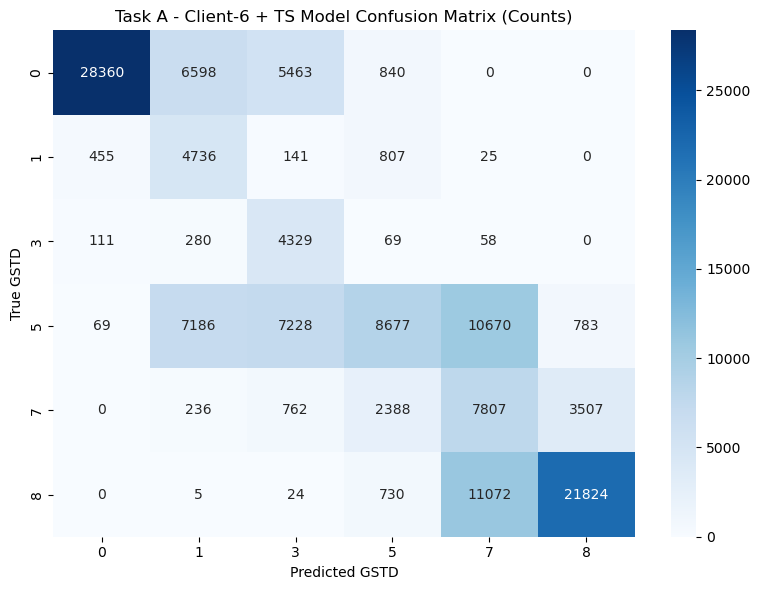

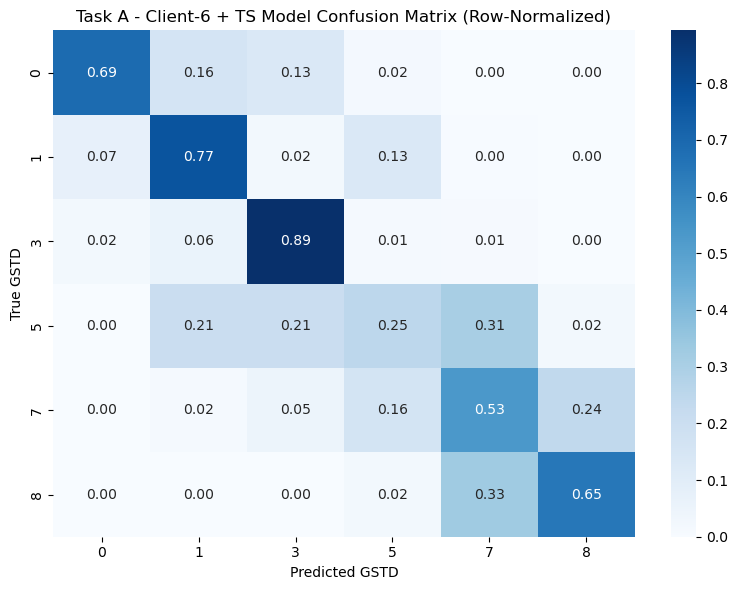


Six-way comparison:


,metric,strict_full_model_run_holdout,proxy_reduced_run_holdout,practical_run_holdout,practical_treatment_holdout,client6_snapshot_run_holdout,client6_ts_run_holdout,improvement_ts_over_snapshot,gap_vs_practical_run_holdout
0,accuracy,0.994965,0.993944,0.987378,0.987851,0.539825,0.559990,0.020164,0.427388
1,balanced_accuracy,0.995141,0.993573,0.986718,0.988317,0.612679,0.629838,0.017159,0.356880
2,macro_f1,0.994145,0.992417,0.982007,0.983683,0.479794,0.501010,0.021217,0.480997
3,weighted_f1,0.994982,0.993967,0.987473,0.987945,0.566464,0.589364,0.022900,0.398109



Saved objects:
- taskA_client6_ts_results
- taskA_client6_ts_report


In [9]:
# ============================================================
# SECTION A9: TASK A USING CLIENT-6 VARIABLES + TIME-SERIES FEATURES
# Goal: test whether temporal structure rescues the 6-variable feasible model
# Honest evaluation: GroupKFold by RUNNO
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupKFold
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from lightgbm import LGBMClassifier

# Start from the six feasible variables used in Task B.
client6_features = ["TMND", "PREC", "SRAD", "TMXD", "TAVD", "NURTD"]

missing_client6 = [c for c in client6_features if c not in df.columns]
if missing_client6:
    raise ValueError(f"Missing client-feasible columns: {missing_client6}")

# Sort for proper within-run feature engineering
sort_cols = [c for c in ["RUNNO", "DATE", "DAP"] if c in df.columns]
df_ts = df.copy().sort_values(sort_cols).reset_index(drop=True)

# Build time-series features within each RUNNO
lag_steps = [1, 3, 7]
roll_windows = [3, 7]

for col in client6_features:
    # lags
    for lag in lag_steps:
        df_ts[f"{col}_lag{lag}"] = df_ts.groupby("RUNNO")[col].shift(lag)

    # first difference
    df_ts[f"{col}_diff1"] = df_ts.groupby("RUNNO")[col].diff(1)

    # rolling means based on shifted values only (avoid same-row leakage from future not an issue,
    # but shift(1) keeps it strictly prior-history based)
    for win in roll_windows:
        df_ts[f"{col}_rollmean{win}"] = (
            df_ts.groupby("RUNNO")[col]
            .transform(lambda s: s.shift(1).rolling(window=win, min_periods=1).mean())
        )

# Define final feature set
client6_ts_features = client6_features.copy()

for col in client6_features:
    client6_ts_features += [f"{col}_lag{lag}" for lag in lag_steps]
    client6_ts_features += [f"{col}_diff1"]
    client6_ts_features += [f"{col}_rollmean{win}" for win in roll_windows]

print("Base client-6 feature count:", len(client6_features))
print("Client-6 + TS feature count:", len(client6_ts_features))

print("\nExample TS features:")
print(client6_ts_features[:25])

X_client6_ts = df_ts[client6_ts_features].copy()
y_client6_ts = df_ts["GSTD"].astype(int).copy()
groups_client6_ts = df_ts["RUNNO"].copy()

print("\nShape of X_client6_ts:", X_client6_ts.shape)

print("\nTop missingness rates:")
display(
    X_client6_ts.isna().mean().sort_values(ascending=False).head(20).to_frame("missing_rate")
)

# GroupKFold by RUNNO
n_splits = 5
gkf_client6_ts = GroupKFold(n_splits=n_splits)

classes = np.sort(y_client6_ts.unique())
class_names = [str(c) for c in classes]

oof_pred_client6_ts = np.zeros(len(y_client6_ts), dtype=int)
fold_rows_client6_ts = []

for fold, (train_idx, valid_idx) in enumerate(
    gkf_client6_ts.split(X_client6_ts, y_client6_ts, groups=groups_client6_ts), start=1
):
    print("=" * 70)
    print(f"Client-6 + TS Model Fold {fold}/{n_splits}")

    X_train, X_valid = X_client6_ts.iloc[train_idx], X_client6_ts.iloc[valid_idx]
    y_train, y_valid = y_client6_ts.iloc[train_idx], y_client6_ts.iloc[valid_idx]

    model_client6_ts = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("clf", LGBMClassifier(
            objective="multiclass",
            num_class=len(classes),
            n_estimators=400,
            learning_rate=0.05,
            num_leaves=31,
            max_depth=-1,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=42,
            class_weight="balanced",
            n_jobs=-1,
            verbosity=-1
        ))
    ])

    model_client6_ts.fit(X_train, y_train)
    valid_pred = model_client6_ts.predict(X_valid)

    oof_pred_client6_ts[valid_idx] = valid_pred

    fold_acc = accuracy_score(y_valid, valid_pred)
    fold_bal_acc = balanced_accuracy_score(y_valid, valid_pred)
    fold_macro_f1 = f1_score(y_valid, valid_pred, average="macro")
    fold_weighted_f1 = f1_score(y_valid, valid_pred, average="weighted")

    fold_rows_client6_ts.append({
        "fold": fold,
        "accuracy": fold_acc,
        "balanced_accuracy": fold_bal_acc,
        "macro_f1": fold_macro_f1,
        "weighted_f1": fold_weighted_f1
    })

    print(f"Accuracy           : {fold_acc:.4f}")
    print(f"Balanced Accuracy  : {fold_bal_acc:.4f}")
    print(f"Macro F1           : {fold_macro_f1:.4f}")
    print(f"Weighted F1        : {fold_weighted_f1:.4f}")

# Fold summary
client6_ts_results = pd.DataFrame(fold_rows_client6_ts)

print("\n" + "=" * 70)
print("CLIENT-6 + TS MODEL FOLD RESULTS")
display(client6_ts_results)

print("\nClient-6 + TS mean CV metrics:")
display(
    client6_ts_results[["accuracy", "balanced_accuracy", "macro_f1", "weighted_f1"]]
    .mean()
    .to_frame("mean")
)

# Overall OOF results
overall_acc_client6_ts = accuracy_score(y_client6_ts, oof_pred_client6_ts)
overall_bal_acc_client6_ts = balanced_accuracy_score(y_client6_ts, oof_pred_client6_ts)
overall_macro_f1_client6_ts = f1_score(y_client6_ts, oof_pred_client6_ts, average="macro")
overall_weighted_f1_client6_ts = f1_score(y_client6_ts, oof_pred_client6_ts, average="weighted")

print("\n" + "=" * 70)
print("CLIENT-6 + TS OVERALL OOF RESULTS")
print(f"Accuracy           : {overall_acc_client6_ts:.4f}")
print(f"Balanced Accuracy  : {overall_bal_acc_client6_ts:.4f}")
print(f"Macro F1           : {overall_macro_f1_client6_ts:.4f}")
print(f"Weighted F1        : {overall_weighted_f1_client6_ts:.4f}")

# Classification report
report_client6_ts = classification_report(
    y_client6_ts,
    oof_pred_client6_ts,
    labels=classes,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)
report_client6_ts_df = pd.DataFrame(report_client6_ts).T

print("\nClient-6 + TS Classification Report (OOF):")
display(report_client6_ts_df)

# Confusion matrices
cm_client6_ts = confusion_matrix(y_client6_ts, oof_pred_client6_ts, labels=classes)
cm_client6_ts_norm = cm_client6_ts.astype(float) / cm_client6_ts.sum(axis=1, keepdims=True)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_client6_ts,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Task A - Client-6 + TS Model Confusion Matrix (Counts)")
plt.xlabel("Predicted GSTD")
plt.ylabel("True GSTD")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_client6_ts_norm,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Task A - Client-6 + TS Model Confusion Matrix (Row-Normalized)")
plt.xlabel("Predicted GSTD")
plt.ylabel("True GSTD")
plt.tight_layout()
plt.show()

# Compare client-6 snapshot vs client-6 + TS vs broader Task A models
comparison_6way = pd.DataFrame({
    "metric": ["accuracy", "balanced_accuracy", "macro_f1", "weighted_f1"],
    "strict_full_model_run_holdout": [
        overall_acc,
        overall_bal_acc,
        overall_macro_f1,
        overall_weighted_f1
    ],
    "proxy_reduced_run_holdout": [
        overall_acc_red,
        overall_bal_acc_red,
        overall_macro_f1_red,
        overall_weighted_f1_red
    ],
    "practical_run_holdout": [
        overall_acc_prac,
        overall_bal_acc_prac,
        overall_macro_f1_prac,
        overall_weighted_f1_prac
    ],
    "practical_treatment_holdout": [
        overall_acc_treat,
        overall_bal_acc_treat,
        overall_macro_f1_treat,
        overall_weighted_f1_treat
    ],
    "client6_snapshot_run_holdout": [
        overall_acc_client6,
        overall_bal_acc_client6,
        overall_macro_f1_client6,
        overall_weighted_f1_client6
    ],
    "client6_ts_run_holdout": [
        overall_acc_client6_ts,
        overall_bal_acc_client6_ts,
        overall_macro_f1_client6_ts,
        overall_weighted_f1_client6_ts
    ]
})

comparison_6way["improvement_ts_over_snapshot"] = (
    comparison_6way["client6_ts_run_holdout"] - comparison_6way["client6_snapshot_run_holdout"]
)

comparison_6way["gap_vs_practical_run_holdout"] = (
    comparison_6way["practical_run_holdout"] - comparison_6way["client6_ts_run_holdout"]
)

print("\nSix-way comparison:")
display(comparison_6way)

# Save these tables as notebook objects for later export or reuse. outputs
taskA_client6_ts_results = client6_ts_results.copy()
taskA_client6_ts_report = report_client6_ts_df.copy()

print("\nSaved objects:")
print("- taskA_client6_ts_results")
print("- taskA_client6_ts_report")

## Task A Feasibility Summary Before Adding LAID

At this point, Task A shows a strong and well-validated current growth stage classification workflow. Using honest **GroupKFold validation by `RUNNO`**, the broader agronomic models performed extremely well. The **strict full model** achieved near-perfect results, and the **proxy-reduced model** remained almost as strong even after removing the most dominant stage-like variables. This showed that the classifier was not relying only on a small number of shortcut features. A more operational **practical model** built from weather, soil-water, and nutrient-related variables also stayed very strong, and the **treatment-held-out** version of that practical model performed similarly well, suggesting the model generalizes not only to unseen runs but also to unseen treatment conditions.

We then tested a much harder operational scenario using only the **6 client-feasible variables from Task B**: `TMND`, `PREC`, `SRAD`, `TMXD`, `TAVD`, and `NURTD`. That model performed much worse, with macro F1 dropping to about **0.50**, indicating that these six variables alone are not sufficient for reliable multiclass current growth stage classification. Adding **time-series features** to the same 6-variable set improved performance slightly, raising macro F1 to about **0.52**, so recent history does add useful signal. However, the improvement was modest, and the model still remained far below the broader practical Task A model. This suggests that temporal context helps, but historical weather and input patterns alone still do not provide enough direct crop-state information to recover exact current growth stage accurately.

Because the professor specifically asked us to consider **LAI / LAID**, the next step is to test whether adding this biologically meaningful canopy-state variable can materially strengthen the feasible-set model. Rather than testing LAID by itself first, the more useful experiment is to add **LAID to the 6 client-feasible variables** and see how much performance improves. After that, we can test **Client-6 + LAID + time-series features** to determine whether the combination of a direct canopy signal plus short-term temporal history can close more of the gap between the limited feasible set and the stronger practical Task A model.

Using features:
['TMND', 'PREC', 'SRAD', 'TMXD', 'TAVD', 'NURTD', 'LAID']

Shape: (135240, 7)

Missingness by feature:


,missing_rate
TMND,0.0
PREC,0.0
SRAD,0.0
TMXD,0.0
TAVD,0.0
NURTD,0.0
LAID,0.0


Client-6 + LAID Model Fold 1/5
Client-6 + LAID Model Fold 2/5
Client-6 + LAID Model Fold 3/5
Client-6 + LAID Model Fold 4/5
Client-6 + LAID Model Fold 5/5

CLIENT-6 + LAID FOLD RESULTS


,fold,accuracy,balanced_accuracy,macro_f1,weighted_f1
0,1,0.784420,0.801632,0.716587,0.797780
1,2,0.767340,0.789431,0.699778,0.781323
2,3,0.777913,0.794228,0.710670,0.790982
3,4,0.779688,0.800163,0.713478,0.791831
4,5,0.774956,0.797319,0.708044,0.787953



Client-6 + LAID mean CV metrics:


,mean
accuracy,0.776863
balanced_accuracy,0.796554
macro_f1,0.709711
weighted_f1,0.789974



CLIENT-6 + LAID OVERALL OOF RESULTS
Accuracy           : 0.7769
Balanced Accuracy  : 0.7965
Macro F1           : 0.7097
Weighted F1        : 0.7900

Client-6 + LAID Classification Report (OOF):


,precision,recall,f1-score,support
0,0.995528,0.895543,0.942892,41261.000000
1,0.495618,0.908339,0.641315,6164.000000
3,0.415587,0.866928,0.561840,4847.000000
5,0.892003,0.587496,0.708413,34613.000000
7,0.459651,0.697075,0.553997,14700.000000
8,0.876806,0.823919,0.849540,33655.000000
accuracy,0.776863,0.776863,0.776863,0.776863
macro avg,0.689199,0.796550,0.709666,135240.000000
weighted avg,0.837670,0.776863,0.789976,135240.000000


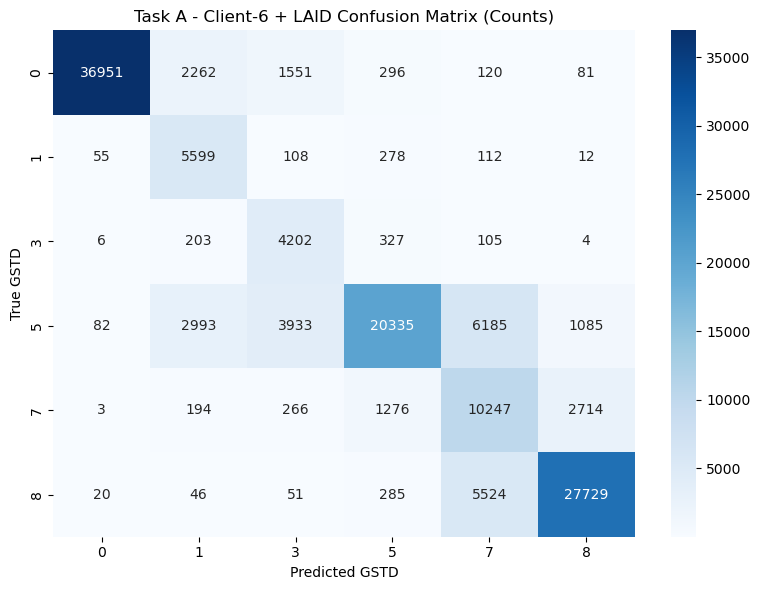

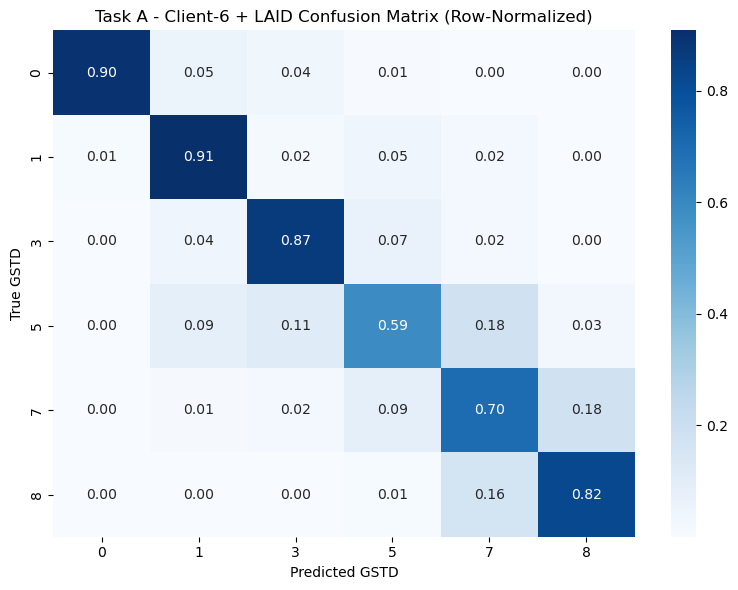


Comparison including Client-6 + LAID:


,metric,client6_snapshot_run_holdout,client6_ts_run_holdout,client6_plus_laid_run_holdout,practical_run_holdout,improvement_over_client6_snapshot,gap_vs_practical_run_holdout
0,accuracy,0.539825,0.559990,0.776863,0.987378,0.237038,0.210515
1,balanced_accuracy,0.612679,0.629838,0.796550,0.986718,0.183871,0.190168
2,macro_f1,0.479794,0.501010,0.709666,0.982007,0.229873,0.272341
3,weighted_f1,0.566464,0.589364,0.789976,0.987473,0.223512,0.197497



Saved objects:
- taskA_client6_lai_results
- taskA_client6_lai_report


In [10]:
# ============================================================
# SECTION A10: TASK A USING CLIENT-6 VARIABLES + LAID
# Feasibility-constrained model with professor-requested canopy signal
# Honest evaluation: GroupKFold by RUNNO
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupKFold
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from lightgbm import LGBMClassifier

# Use LAID if it exists, otherwise fall back to LAI.
lai_col = None
if "LAID" in df.columns:
    lai_col = "LAID"
elif "LAI" in df.columns:
    lai_col = "LAI"
else:
    raise ValueError("Neither LAID nor LAI exists in df.")

# Build feature set: client-6 + LAID
client6_plus_lai_features = ["TMND", "PREC", "SRAD", "TMXD", "TAVD", "NURTD", lai_col]

missing_cols = [c for c in client6_plus_lai_features if c not in df.columns]
if missing_cols:
    raise ValueError(f"Missing columns: {missing_cols}")

X_client6_lai = df[client6_plus_lai_features].copy()
y_client6_lai = y.copy()
groups_client6_lai = groups.copy()

print("Using features:")
print(client6_plus_lai_features)

print("\nShape:", X_client6_lai.shape)

print("\nMissingness by feature:")
display(X_client6_lai.isna().mean().to_frame("missing_rate"))

# GroupKFold by RUNNO
n_splits = 5
gkf_client6_lai = GroupKFold(n_splits=n_splits)

classes = np.sort(y_client6_lai.unique())
class_names = [str(c) for c in classes]

oof_pred_client6_lai = np.zeros(len(y_client6_lai), dtype=int)
fold_rows_client6_lai = []

for fold, (train_idx, valid_idx) in enumerate(
    gkf_client6_lai.split(X_client6_lai, y_client6_lai, groups=groups_client6_lai), start=1
):
    print("=" * 70)
    print(f"Client-6 + LAID Model Fold {fold}/{n_splits}")

    X_train, X_valid = X_client6_lai.iloc[train_idx], X_client6_lai.iloc[valid_idx]
    y_train, y_valid = y_client6_lai.iloc[train_idx], y_client6_lai.iloc[valid_idx]

    model_client6_lai = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("clf", LGBMClassifier(
            objective="multiclass",
            num_class=len(classes),
            n_estimators=300,
            learning_rate=0.05,
            num_leaves=31,
            max_depth=-1,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=42,
            class_weight="balanced",
            n_jobs=-1,
            verbosity=-1
        ))
    ])

    model_client6_lai.fit(X_train, y_train)
    valid_pred = model_client6_lai.predict(X_valid)

    oof_pred_client6_lai[valid_idx] = valid_pred

    fold_rows_client6_lai.append({
        "fold": fold,
        "accuracy": accuracy_score(y_valid, valid_pred),
        "balanced_accuracy": balanced_accuracy_score(y_valid, valid_pred),
        "macro_f1": f1_score(y_valid, valid_pred, average="macro"),
        "weighted_f1": f1_score(y_valid, valid_pred, average="weighted")
    })

client6_lai_results = pd.DataFrame(fold_rows_client6_lai)

print("\nCLIENT-6 + LAID FOLD RESULTS")
display(client6_lai_results)

print("\nClient-6 + LAID mean CV metrics:")
display(
    client6_lai_results[["accuracy", "balanced_accuracy", "macro_f1", "weighted_f1"]]
    .mean()
    .to_frame("mean")
)

overall_acc_client6_lai = accuracy_score(y_client6_lai, oof_pred_client6_lai)
overall_bal_acc_client6_lai = balanced_accuracy_score(y_client6_lai, oof_pred_client6_lai)
overall_macro_f1_client6_lai = f1_score(y_client6_lai, oof_pred_client6_lai, average="macro")
overall_weighted_f1_client6_lai = f1_score(y_client6_lai, oof_pred_client6_lai, average="weighted")

print("\nCLIENT-6 + LAID OVERALL OOF RESULTS")
print(f"Accuracy           : {overall_acc_client6_lai:.4f}")
print(f"Balanced Accuracy  : {overall_bal_acc_client6_lai:.4f}")
print(f"Macro F1           : {overall_macro_f1_client6_lai:.4f}")
print(f"Weighted F1        : {overall_weighted_f1_client6_lai:.4f}")

report_client6_lai = classification_report(
    y_client6_lai,
    oof_pred_client6_lai,
    labels=classes,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)
report_client6_lai_df = pd.DataFrame(report_client6_lai).T

print("\nClient-6 + LAID Classification Report (OOF):")
display(report_client6_lai_df)

cm_client6_lai = confusion_matrix(y_client6_lai, oof_pred_client6_lai, labels=classes)
cm_client6_lai_norm = cm_client6_lai.astype(float) / cm_client6_lai.sum(axis=1, keepdims=True)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_client6_lai,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Task A - Client-6 + LAID Confusion Matrix (Counts)")
plt.xlabel("Predicted GSTD")
plt.ylabel("True GSTD")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_client6_lai_norm,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Task A - Client-6 + LAID Confusion Matrix (Row-Normalized)")
plt.xlabel("Predicted GSTD")
plt.ylabel("True GSTD")
plt.tight_layout()
plt.show()

comparison_client6_lai = pd.DataFrame({
    "metric": ["accuracy", "balanced_accuracy", "macro_f1", "weighted_f1"],
    "client6_snapshot_run_holdout": [
        overall_acc_client6, overall_bal_acc_client6, overall_macro_f1_client6, overall_weighted_f1_client6
    ],
    "client6_ts_run_holdout": [
        overall_acc_client6_ts, overall_bal_acc_client6_ts, overall_macro_f1_client6_ts, overall_weighted_f1_client6_ts
    ],
    "client6_plus_laid_run_holdout": [
        overall_acc_client6_lai, overall_bal_acc_client6_lai, overall_macro_f1_client6_lai, overall_weighted_f1_client6_lai
    ],
    "practical_run_holdout": [
        overall_acc_prac, overall_bal_acc_prac, overall_macro_f1_prac, overall_weighted_f1_prac
    ]
})

comparison_client6_lai["improvement_over_client6_snapshot"] = (
    comparison_client6_lai["client6_plus_laid_run_holdout"] - comparison_client6_lai["client6_snapshot_run_holdout"]
)

comparison_client6_lai["gap_vs_practical_run_holdout"] = (
    comparison_client6_lai["practical_run_holdout"] - comparison_client6_lai["client6_plus_laid_run_holdout"]
)

print("\nComparison including Client-6 + LAID:")
display(comparison_client6_lai)

taskA_client6_lai_results = client6_lai_results.copy()
taskA_client6_lai_report = report_client6_lai_df.copy()

print("\nSaved objects:")
print("- taskA_client6_lai_results")
print("- taskA_client6_lai_report")

Base feature count: 7
Client-6 + LAID + TS feature count: 49

Example features:
['TMND', 'PREC', 'SRAD', 'TMXD', 'TAVD', 'NURTD', 'LAID', 'TMND_lag1', 'TMND_lag3', 'TMND_lag7', 'TMND_diff1', 'TMND_rollmean3', 'TMND_rollmean7', 'PREC_lag1', 'PREC_lag3', 'PREC_lag7', 'PREC_diff1', 'PREC_rollmean3', 'PREC_rollmean7', 'SRAD_lag1', 'SRAD_lag3', 'SRAD_lag7', 'SRAD_diff1', 'SRAD_rollmean3', 'SRAD_rollmean7', 'TMXD_lag1', 'TMXD_lag3', 'TMXD_lag7', 'TMXD_diff1', 'TMXD_rollmean3']

Shape: (135240, 49)

Top missingness rates:


,missing_rate
TMXD_lag7,0.050725
NURTD_lag7,0.050725
LAID_lag7,0.050725
TAVD_lag7,0.050725
SRAD_lag7,0.050725
PREC_lag7,0.050725
TMND_lag7,0.050725
TMXD_lag3,0.021739
TAVD_lag3,0.021739
SRAD_lag3,0.021739


Client-6 + LAID + TS Model Fold 1/5
Client-6 + LAID + TS Model Fold 2/5
Client-6 + LAID + TS Model Fold 3/5
Client-6 + LAID + TS Model Fold 4/5
Client-6 + LAID + TS Model Fold 5/5

CLIENT-6 + LAID + TS FOLD RESULTS


,fold,accuracy,balanced_accuracy,macro_f1,weighted_f1
0,1,0.938443,0.941778,0.929129,0.940021
1,2,0.931307,0.936663,0.925047,0.933295
2,3,0.934857,0.944748,0.927556,0.937178
3,4,0.932749,0.935361,0.920718,0.934421
4,5,0.930087,0.932905,0.922108,0.931945



Client-6 + LAID + TS mean CV metrics:


,mean
accuracy,0.933489
balanced_accuracy,0.938291
macro_f1,0.924912
weighted_f1,0.935372



CLIENT-6 + LAID + TS OVERALL OOF RESULTS
Accuracy           : 0.9335
Balanced Accuracy  : 0.9383
Macro F1           : 0.9249
Weighted F1        : 0.9354

Client-6 + LAID + TS Classification Report (OOF):


,precision,recall,f1-score,support
0,0.998707,0.991978,0.995331,41261.000000
1,0.955328,0.981830,0.968397,6164.000000
3,0.921390,0.979369,0.949495,4847.000000
5,0.965315,0.898940,0.930946,34613.000000
7,0.706473,0.866463,0.778331,14700.000000
8,0.943276,0.911128,0.926923,33655.000000
accuracy,0.933489,0.933489,0.933489,0.933489
macro avg,0.915081,0.938284,0.924904,135240.000000
weighted avg,0.939854,0.933489,0.935371,135240.000000


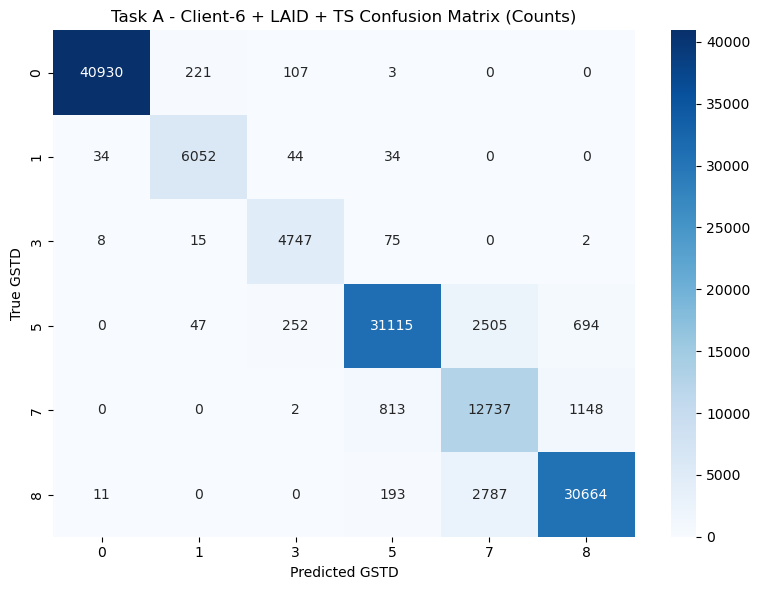

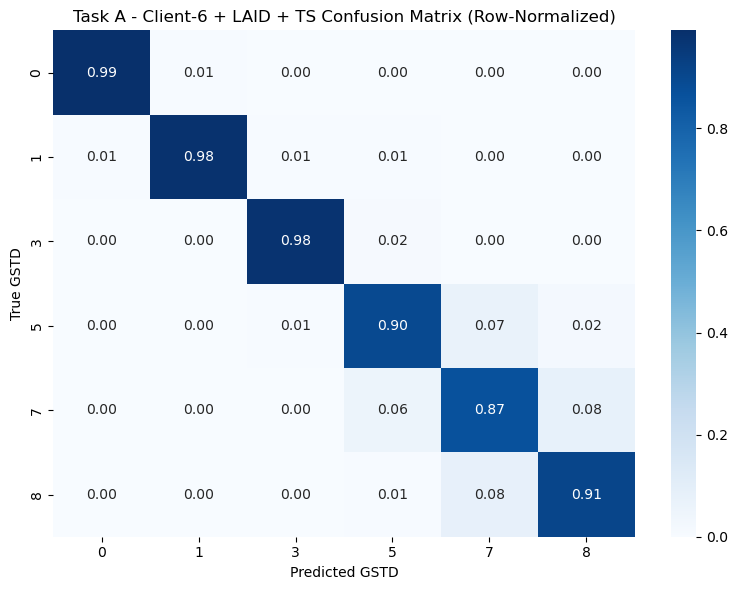


Comparison including Client-6 + LAID + TS:


,metric,client6_snapshot_run_holdout,client6_ts_run_holdout,client6_plus_laid_run_holdout,client6_plus_laid_ts_run_holdout,practical_run_holdout,improvement_ts_over_client6_laid,gap_vs_practical_run_holdout
0,accuracy,0.539825,0.559990,0.776863,0.933489,0.987378,0.156625,0.053889
1,balanced_accuracy,0.612679,0.629838,0.796550,0.938284,0.986718,0.141734,0.048434
2,macro_f1,0.479794,0.501010,0.709666,0.924904,0.982007,0.215238,0.057104
3,weighted_f1,0.566464,0.589364,0.789976,0.935371,0.987473,0.145396,0.052101



Saved objects:
- taskA_client6_lai_ts_results
- taskA_client6_lai_ts_report


In [11]:
# ============================================================
# SECTION A11: TASK A USING CLIENT-6 + LAID + TIME-SERIES FEATURES
# Honest evaluation: GroupKFold by RUNNO
# Goal: test whether LAID plus short-term history closes more of the gap
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupKFold
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from lightgbm import LGBMClassifier

# Use LAID if it exists, otherwise fall back to LAI.
lai_col = None
if "LAID" in df.columns:
    lai_col = "LAID"
elif "LAI" in df.columns:
    lai_col = "LAI"
else:
    raise ValueError("Neither LAID nor LAI exists in df.")

# Base features: client-6 + LAID
base_features = ["TMND", "PREC", "SRAD", "TMXD", "TAVD", "NURTD", lai_col]

missing_cols = [c for c in base_features if c not in df.columns]
if missing_cols:
    raise ValueError(f"Missing columns: {missing_cols}")

# Sort for within-run TS engineering
sort_cols = [c for c in ["RUNNO", "DATE", "DAP"] if c in df.columns]
df_client6_lai_ts = df.copy().sort_values(sort_cols).reset_index(drop=True)

# Build TS features within RUNNO only
lag_steps = [1, 3, 7]
roll_windows = [3, 7]

for col in base_features:
    for lag in lag_steps:
        df_client6_lai_ts[f"{col}_lag{lag}"] = (
            df_client6_lai_ts.groupby("RUNNO")[col].shift(lag)
        )

    df_client6_lai_ts[f"{col}_diff1"] = (
        df_client6_lai_ts.groupby("RUNNO")[col].diff(1)
    )

    for win in roll_windows:
        df_client6_lai_ts[f"{col}_rollmean{win}"] = (
            df_client6_lai_ts.groupby("RUNNO")[col]
            .transform(lambda s: s.shift(1).rolling(window=win, min_periods=1).mean())
        )

# Final feature list
client6_lai_ts_features = base_features.copy()

for col in base_features:
    client6_lai_ts_features += [f"{col}_lag{lag}" for lag in lag_steps]
    client6_lai_ts_features += [f"{col}_diff1"]
    client6_lai_ts_features += [f"{col}_rollmean{win}" for win in roll_windows]

print("Base feature count:", len(base_features))
print("Client-6 + LAID + TS feature count:", len(client6_lai_ts_features))

print("\nExample features:")
print(client6_lai_ts_features[:30])

X_client6_lai_ts = df_client6_lai_ts[client6_lai_ts_features].copy()
y_client6_lai_ts = df_client6_lai_ts["GSTD"].astype(int).copy()
groups_client6_lai_ts = df_client6_lai_ts["RUNNO"].copy()

print("\nShape:", X_client6_lai_ts.shape)

print("\nTop missingness rates:")
display(
    X_client6_lai_ts.isna().mean().sort_values(ascending=False).head(20).to_frame("missing_rate")
)

# GroupKFold by RUNNO
n_splits = 5
gkf_client6_lai_ts = GroupKFold(n_splits=n_splits)

classes = np.sort(y_client6_lai_ts.unique())
class_names = [str(c) for c in classes]

oof_pred_client6_lai_ts = np.zeros(len(y_client6_lai_ts), dtype=int)
fold_rows_client6_lai_ts = []

for fold, (train_idx, valid_idx) in enumerate(
    gkf_client6_lai_ts.split(X_client6_lai_ts, y_client6_lai_ts, groups=groups_client6_lai_ts), start=1
):
    print("=" * 70)
    print(f"Client-6 + LAID + TS Model Fold {fold}/{n_splits}")

    X_train, X_valid = X_client6_lai_ts.iloc[train_idx], X_client6_lai_ts.iloc[valid_idx]
    y_train, y_valid = y_client6_lai_ts.iloc[train_idx], y_client6_lai_ts.iloc[valid_idx]

    model_client6_lai_ts = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("clf", LGBMClassifier(
            objective="multiclass",
            num_class=len(classes),
            n_estimators=400,
            learning_rate=0.05,
            num_leaves=31,
            max_depth=-1,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=42,
            class_weight="balanced",
            n_jobs=-1,
            verbosity=-1
        ))
    ])

    model_client6_lai_ts.fit(X_train, y_train)
    valid_pred = model_client6_lai_ts.predict(X_valid)

    oof_pred_client6_lai_ts[valid_idx] = valid_pred

    fold_rows_client6_lai_ts.append({
        "fold": fold,
        "accuracy": accuracy_score(y_valid, valid_pred),
        "balanced_accuracy": balanced_accuracy_score(y_valid, valid_pred),
        "macro_f1": f1_score(y_valid, valid_pred, average="macro"),
        "weighted_f1": f1_score(y_valid, valid_pred, average="weighted")
    })

client6_lai_ts_results = pd.DataFrame(fold_rows_client6_lai_ts)

print("\nCLIENT-6 + LAID + TS FOLD RESULTS")
display(client6_lai_ts_results)

print("\nClient-6 + LAID + TS mean CV metrics:")
display(
    client6_lai_ts_results[["accuracy", "balanced_accuracy", "macro_f1", "weighted_f1"]]
    .mean()
    .to_frame("mean")
)

overall_acc_client6_lai_ts = accuracy_score(y_client6_lai_ts, oof_pred_client6_lai_ts)
overall_bal_acc_client6_lai_ts = balanced_accuracy_score(y_client6_lai_ts, oof_pred_client6_lai_ts)
overall_macro_f1_client6_lai_ts = f1_score(y_client6_lai_ts, oof_pred_client6_lai_ts, average="macro")
overall_weighted_f1_client6_lai_ts = f1_score(y_client6_lai_ts, oof_pred_client6_lai_ts, average="weighted")

print("\nCLIENT-6 + LAID + TS OVERALL OOF RESULTS")
print(f"Accuracy           : {overall_acc_client6_lai_ts:.4f}")
print(f"Balanced Accuracy  : {overall_bal_acc_client6_lai_ts:.4f}")
print(f"Macro F1           : {overall_macro_f1_client6_lai_ts:.4f}")
print(f"Weighted F1        : {overall_weighted_f1_client6_lai_ts:.4f}")

report_client6_lai_ts = classification_report(
    y_client6_lai_ts,
    oof_pred_client6_lai_ts,
    labels=classes,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)
report_client6_lai_ts_df = pd.DataFrame(report_client6_lai_ts).T

print("\nClient-6 + LAID + TS Classification Report (OOF):")
display(report_client6_lai_ts_df)

cm_client6_lai_ts = confusion_matrix(y_client6_lai_ts, oof_pred_client6_lai_ts, labels=classes)
cm_client6_lai_ts_norm = cm_client6_lai_ts.astype(float) / cm_client6_lai_ts.sum(axis=1, keepdims=True)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_client6_lai_ts,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Task A - Client-6 + LAID + TS Confusion Matrix (Counts)")
plt.xlabel("Predicted GSTD")
plt.ylabel("True GSTD")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_client6_lai_ts_norm,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Task A - Client-6 + LAID + TS Confusion Matrix (Row-Normalized)")
plt.xlabel("Predicted GSTD")
plt.ylabel("True GSTD")
plt.tight_layout()
plt.show()

comparison_client6_lai_ts = pd.DataFrame({
    "metric": ["accuracy", "balanced_accuracy", "macro_f1", "weighted_f1"],
    "client6_snapshot_run_holdout": [
        overall_acc_client6, overall_bal_acc_client6, overall_macro_f1_client6, overall_weighted_f1_client6
    ],
    "client6_ts_run_holdout": [
        overall_acc_client6_ts, overall_bal_acc_client6_ts, overall_macro_f1_client6_ts, overall_weighted_f1_client6_ts
    ],
    "client6_plus_laid_run_holdout": [
        overall_acc_client6_lai, overall_bal_acc_client6_lai, overall_macro_f1_client6_lai, overall_weighted_f1_client6_lai
    ],
    "client6_plus_laid_ts_run_holdout": [
        overall_acc_client6_lai_ts, overall_bal_acc_client6_lai_ts, overall_macro_f1_client6_lai_ts, overall_weighted_f1_client6_lai_ts
    ],
    "practical_run_holdout": [
        overall_acc_prac, overall_bal_acc_prac, overall_macro_f1_prac, overall_weighted_f1_prac
    ]
})

comparison_client6_lai_ts["improvement_ts_over_client6_laid"] = (
    comparison_client6_lai_ts["client6_plus_laid_ts_run_holdout"] -
    comparison_client6_lai_ts["client6_plus_laid_run_holdout"]
)

comparison_client6_lai_ts["gap_vs_practical_run_holdout"] = (
    comparison_client6_lai_ts["practical_run_holdout"] -
    comparison_client6_lai_ts["client6_plus_laid_ts_run_holdout"]
)

print("\nComparison including Client-6 + LAID + TS:")
display(comparison_client6_lai_ts)

# Save these tables as notebook objects for later export or reuse. outputs
taskA_client6_lai_ts_results = client6_lai_ts_results.copy()
taskA_client6_lai_ts_report = report_client6_lai_ts_df.copy()

print("\nSaved objects:")
print("- taskA_client6_lai_ts_results")
print("- taskA_client6_lai_ts_report")

In [12]:
# ============================================================
# SECTION A12: FINAL TASK A MODEL COMPARISON TABLE
# One clean table with validation strategy shown separately
# ============================================================

import pandas as pd
import numpy as np

# Put every model into one comparison table so the final output is not repetitive.
# We separate the model name from the validation strategy so each row is easier to read.
comparison_clean = pd.DataFrame([
    {
        "model": "1. Strict Full",
        "validation_strategy": "Run-held-out GroupKFold by RUNNO",
        "feature_set": "Full numeric benchmark",
        "accuracy": overall_acc,
        "balanced_accuracy": overall_bal_acc,
        "macro_f1": overall_macro_f1,
        "weighted_f1": overall_weighted_f1
    },
    {
        "model": "2. Proxy-Reduced",
        "validation_strategy": "Run-held-out GroupKFold by RUNNO",
        "feature_set": "Full set after removing strongest proxy features",
        "accuracy": overall_acc_red,
        "balanced_accuracy": overall_bal_acc_red,
        "macro_f1": overall_macro_f1_red,
        "weighted_f1": overall_weighted_f1_red
    },
    {
        "model": "3. Practical",
        "validation_strategy": "Run-held-out GroupKFold by RUNNO",
        "feature_set": "Practical agronomic feature set",
        "accuracy": overall_acc_prac,
        "balanced_accuracy": overall_bal_acc_prac,
        "macro_f1": overall_macro_f1_prac,
        "weighted_f1": overall_weighted_f1_prac
    },
    {
        "model": "4. Practical",
        "validation_strategy": "Treatment-held-out GroupKFold by TRTNO",
        "feature_set": "Practical agronomic feature set",
        "accuracy": overall_acc_treat,
        "balanced_accuracy": overall_bal_acc_treat,
        "macro_f1": overall_macro_f1_treat,
        "weighted_f1": overall_weighted_f1_treat
    },
    {
        "model": "5. Client-6 Snapshot",
        "validation_strategy": "Run-held-out GroupKFold by RUNNO",
        "feature_set": "TMND, PREC, SRAD, TMXD, TAVD, NURTD",
        "accuracy": overall_acc_client6,
        "balanced_accuracy": overall_bal_acc_client6,
        "macro_f1": overall_macro_f1_client6,
        "weighted_f1": overall_weighted_f1_client6
    },
    {
        "model": "6. Client-6 + Time-Series",
        "validation_strategy": "Run-held-out GroupKFold by RUNNO",
        "feature_set": "Client-6 plus lag, rolling, and change features",
        "accuracy": overall_acc_client6_ts,
        "balanced_accuracy": overall_bal_acc_client6_ts,
        "macro_f1": overall_macro_f1_client6_ts,
        "weighted_f1": overall_weighted_f1_client6_ts
    },
    {
        "model": "7. Client-6 + LAID",
        "validation_strategy": "Run-held-out GroupKFold by RUNNO",
        "feature_set": "Client-6 plus LAID",
        "accuracy": overall_acc_client6_lai,
        "balanced_accuracy": overall_bal_acc_client6_lai,
        "macro_f1": overall_macro_f1_client6_lai,
        "weighted_f1": overall_weighted_f1_client6_lai
    }
])

# Add the LAID + time-series row after that section has been run.
if "overall_acc_client6_lai_ts" in globals():
    comparison_clean = pd.concat([
        comparison_clean,
        pd.DataFrame([{
            "model": "8. Client-6 + LAID + Time-Series",
            "validation_strategy": "Run-held-out GroupKFold by RUNNO",
            "feature_set": "Client-6 plus LAID plus lag, rolling, and change features",
            "accuracy": overall_acc_client6_lai_ts,
            "balanced_accuracy": overall_bal_acc_client6_lai_ts,
            "macro_f1": overall_macro_f1_client6_lai_ts,
            "weighted_f1": overall_weighted_f1_client6_lai_ts
        }])
    ], ignore_index=True)

# These comparison columns help explain the business meaning of the table.
# A positive gap vs practical means the model is below the practical benchmark.
# A positive gain vs Client-6 means the model improved over the smallest feasible baseline.
practical_macro_f1 = overall_macro_f1_prac
client6_macro_f1 = overall_macro_f1_client6

comparison_clean["macro_f1_gap_vs_practical"] = practical_macro_f1 - comparison_clean["macro_f1"]
comparison_clean["macro_f1_gain_vs_client6"] = comparison_clean["macro_f1"] - client6_macro_f1
comparison_clean["accuracy_gain_vs_client6"] = comparison_clean["accuracy"] - overall_acc_client6

# Round the display version so it is easier to read in the notebook and handoff package.
comparison_display = comparison_clean.copy()
metric_cols = [
    "accuracy", "balanced_accuracy", "macro_f1", "weighted_f1",
    "macro_f1_gap_vs_practical", "macro_f1_gain_vs_client6", "accuracy_gain_vs_client6"
]
comparison_display[metric_cols] = comparison_display[metric_cols].round(4)

# Reorder the columns for a cleaner final view.
comparison_display = comparison_display[[
    "model",
    "validation_strategy",
    "feature_set",
    "accuracy",
    "balanced_accuracy",
    "macro_f1",
    "weighted_f1",
    "macro_f1_gap_vs_practical",
    "macro_f1_gain_vs_client6",
    "accuracy_gain_vs_client6"
]]

print("TASK A FINAL MODEL COMPARISON")
display(comparison_display)

# Save the table under both names so later notebooks or exports can reuse it easily.
taskA_comparison_clean = comparison_display.copy()
taskA_comparison_summary = comparison_display.copy()

print("\nSaved objects:")
print("- taskA_comparison_clean")
print("- taskA_comparison_summary")


TASK A FINAL MODEL COMPARISON


,model,validation_strategy,feature_set,accuracy,balanced_accuracy,macro_f1,weighted_f1,macro_f1_gap_vs_practical,macro_f1_gain_vs_client6,accuracy_gain_vs_client6
0,1. Strict Full,Run-held-out GroupKFold by RUNNO,Full numeric benchmark,0.9950,0.9951,0.9941,0.9950,-0.0121,0.5144,0.4551
1,2. Proxy-Reduced,Run-held-out GroupKFold by RUNNO,Full set after removing strongest proxy features,0.9939,0.9936,0.9924,0.9940,-0.0104,0.5126,0.4541
2,3. Practical,Run-held-out GroupKFold by RUNNO,Practical agronomic feature set,0.9874,0.9867,0.9820,0.9875,0.0000,0.5022,0.4476
3,4. Practical,Treatment-held-out GroupKFold by TRTNO,Practical agronomic feature set,0.9879,0.9883,0.9837,0.9879,-0.0017,0.5039,0.4480
4,5. Client-6 Snapshot,Run-held-out GroupKFold by RUNNO,"TMND, PREC, SRAD, TMXD, TAVD, NURTD",0.5398,0.6127,0.4798,0.5665,0.5022,0.0000,0.0000
5,6. Client-6 + Time-Series,Run-held-out GroupKFold by RUNNO,"Client-6 plus lag, rolling, and change features",0.5600,0.6298,0.5010,0.5894,0.4810,0.0212,0.0202
6,7. Client-6 + LAID,Run-held-out GroupKFold by RUNNO,Client-6 plus LAID,0.7769,0.7965,0.7097,0.7900,0.2723,0.2299,0.2370
7,8. Client-6 + LAID + Time-Series,Run-held-out GroupKFold by RUNNO,"Client-6 plus LAID plus lag, rolling, and chan...",0.9335,0.9383,0.9249,0.9354,0.0571,0.4451,0.3937



Saved objects:
- taskA_comparison_clean
- taskA_comparison_summary


## Final Task A Recommendation and Summary

The final comparison table separates the **model type**, **validation strategy**, and **feature set** so the client can see which results come from run-held-out validation and which result comes from treatment-held-out robustness testing.

This notebook developed and evaluated a series of models for **Task A: current growth stage classification** using the validated dataset and honest grouped validation strategies. The primary benchmark was **GroupKFold by `RUNNO`**, which ensured that the model was evaluated on unseen runs rather than on highly related rows from the same run. Under this setup, the broad agronomic models performed extremely well. The **strict full model** achieved near-perfect performance, and the **proxy-reduced model** remained almost as strong after removing the most dominant stage-like variables. This showed that the result was not driven only by a few shortcut features. A smaller **practical model** using a more operationally realistic subset of variables also performed very strongly, and a **treatment-held-out** version of that practical model produced nearly identical results, indicating that the Task A classifier generalizes well not only to unseen runs but also to unseen treatment conditions.

To assess overfitting more directly, we compared training and validation performance under grouped cross-validation. The practical model showed only a modest train-validation gap, which is expected for LightGBM on a structured multiclass problem, but not large enough to undermine confidence in generalization. This finding was reinforced by the stability of metrics across folds and by the strong treatment-held-out results. Across the strongest Task A models, the main residual errors were concentrated in biologically adjacent later stages, especially **5 vs 7** and **7 vs 8**, which is a believable and acceptable pattern rather than a sign of widespread instability.

A second major goal of the notebook was to test **operational feasibility**. When the model was restricted to the **6 client-feasible variables from Task B** (`TMND`, `PREC`, `SRAD`, `TMXD`, `TAVD`, and `NURTD`), performance dropped sharply, showing that these variables alone are not sufficient for reliable multiclass current growth stage classification. Adding time-series features to those same 6 variables improved performance only modestly, indicating that short-term history contains useful signal but cannot by itself overcome the lack of direct crop-state information. This result suggests that the very small feasible set may be acceptable for the simpler binary Task B transition alert, but not for the harder Task A multiclass stage classification problem.

The final set of experiments showed the importance of adding a biologically meaningful canopy-state signal. When `LAID` was added to the 6 client-feasible variables, performance improved substantially. When **time-series features** were then added on top of **Client-6 + LAID**, the resulting model became very strong and approached the broader practical Task A model. This was the most important feasibility result in the notebook. It suggests that the client may not need the full larger agronomic feature space to achieve strong Task A performance, but they likely do need at least one direct crop-state variable such as `LAID`, together with short-term temporal history.

Overall, this notebook supports four main conclusions. First, **Task A is highly feasible** when a sufficiently rich agronomic feature set is available. Second, the model appears **robust and well-generalized**, with no strong evidence of harmful overfitting under run-held-out or treatment-held-out validation. Third, the original **6 client-feasible Task B variables are not enough** for strong current growth stage classification, even when historical features are added. Fourth, **Client-6 + LAID + time-series features** provides a strong middle-ground solution, combining much better operational feasibility with performance that comes much closer to the strongest practical Task A benchmark. This final progression gives a clear and defensible story for both the professor and the client: current growth stage classification works very well, and a realistic deployment path likely requires a compact feasible set augmented with one biologically meaningful canopy measurement and recent temporal history.